# ENVIRONMENT & MASTER CONFIG

## Install + Imports + Reproducibility

In [1]:
"""
INDOMEME-XAI FULL PIPELINE V2
Single integrated notebook menggantikan pendekatan per-fase di iterasi sebelumnya.
Mengintegrasi semua learning dari Fase 1-2 (pilot study).

Strategi inti:
  - Spektrum 4 varian arsitektur untuk ablasi sistematis
  - Training strategy yang teruji + tambahan R-Drop + cosine annealing
  - XAI 4 metode + perturbation + ROAR (faithfulness gold standard)
  - Incongruity Heatmap POST-HOC (model-agnostic)
"""
import subprocess, sys
def _pip(p): subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", p])
try: import captum
except ImportError: _pip("captum"); import captum

import os, json, random, time, math, re, unicodedata, copy, gc
from pathlib import Path
from collections import Counter
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torch.amp import autocast, GradScaler
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from torchvision import transforms
from transformers import (AutoTokenizer, AutoModel, ViTImageProcessor, ViTModel,
                          get_linear_schedule_with_warmup, get_cosine_schedule_with_warmup)
from sklearn.metrics import (f1_score, accuracy_score, recall_score, precision_score,
                              roc_auc_score, precision_recall_fscore_support,
                              classification_report, confusion_matrix)
from captum.attr import LayerIntegratedGradients
from tqdm.auto import tqdm

def set_seed(seed: int):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    os.environ["PYTHONHASHSEED"] = str(seed)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"PyTorch {torch.__version__}  |  Device: {DEVICE}  |  Captum: {captum.__version__}")
if torch.cuda.is_available(): print(f"GPU: {torch.cuda.get_device_name(0)}")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 455.2/455.2 kB 9.4 MB/s eta 0:00:00
PyTorch 2.10.0+cu128  |  Device: cuda  |  Captum: 0.9.0
GPU: Tesla T4


## Master CONFIG (single source of truth)

In [2]:
KAGGLE_INPUT = Path("/kaggle/input/datasets/reynaldaryansyah")
ROOT_DIR     = KAGGLE_INPUT / "xai-dataset" / "data" / "data"
CSV_PATH     = ROOT_DIR / "processed" / "all_splits.csv"
IMG_DIR      = ROOT_DIR / "images"

OUT_DIR  = Path("/kaggle/working/indomeme_xai_v2")
DIRS = {
    "root":        OUT_DIR,
    "results":     OUT_DIR / "results",
    "figures":     OUT_DIR / "figures",
    "checkpoints": OUT_DIR / "checkpoints",
    "ablation":    OUT_DIR / "ablation",
    "xai":         OUT_DIR / "xai",
    "roar":        OUT_DIR / "roar",
}

RESUME_DATASET = Path("/kaggle/input/datasets/reynaldaryansyah/indomeme-xai-v2-resume/indomeme_xai_v2")
if RESUME_DATASET.exists():
    import shutil
    print("Resume mode: copying cached artifacts...")
    for src in RESUME_DATASET.rglob("*"):
        if src.is_file():
            rel = src.relative_to(RESUME_DATASET)
            dst = OUT_DIR / rel
            dst.parent.mkdir(parents=True, exist_ok=True)
            if not dst.exists():
                shutil.copy2(src, dst)
    print(f"Cached files restored to {OUT_DIR}")
    
for d in DIRS.values(): d.mkdir(parents=True, exist_ok=True)

CONFIG = dict(
    notebook_id      = "indomeme_xai_v2",
    seed             = 42,

    # Encoders
    text_model_name  = "indolem/indobertweet-base-uncased",
    image_model_name = "google/vit-base-patch16-224-in21k",
    freeze_n_layers  = 2,                # was 4 di V1 -> turun karena domain shift meme besar
    max_seq_len      = 128,
    img_size         = 224,
    grid_size        = 14,
    patch_size       = 16,

    # Topic & head
    topic_emb_dim    = 32,
    head_hidden      = 256,
    head_dropout     = 0.3,
    cross_attn_dropout = 0.1,            # NEW: dropout di cross-attn output (mitigasi overfit)
    icam_num_heads   = 8,

    # SupCon (untuk ablasi semua varian)
    supcon_lambda          = 0.3,
    supcon_temperature     = 0.07,
    supcon_proj_hidden     = 128,
    supcon_proj_out        = 128,
    supcon_warmup_epochs   = 3,

    # R-Drop (NEW)
    rdrop_alpha            = 1.0,        # KL weight; 0.0 = off

    # Training
    batch_size       = 32,
    grad_accum       = 2,
    num_epochs       = 15,
    early_stop_pat   = 5,
    grad_clip        = 1.0,

    # Optimizer (3 group LR)
    lr_encoder       = 1e-5,
    lr_fusion        = 3e-5,
    lr_head          = 5e-5,
    weight_decay     = 0.01,
    warmup_ratio     = 0.10,
    scheduler_type   = "cosine",         # "cosine" | "linear"  (NEW: cosine default)

    # Loss
    focal_gamma      = 2.0,
    label_smoothing  = 0.1,
    class_weights    = [0.76, 1.46],

    # Threshold calibration
    thr_search_lo    = 0.40,
    thr_search_hi    = 0.65,
    thr_search_step  = 0.01,

    # Ablation matrix
    ablation_variants = ["A_late_fusion", "B_single_cross_attn", "C_icam_three_stream", "D_no_topic"],
    ablation_seeds    = [42, 123, 2024],

    # Ensemble (Varian B saja)
    ensemble_seeds   = [42, 123, 2024, 7, 999],

    # XAI
    ig_n_steps       = 50,
    ig_internal_bs   = 8,

    # ROAR
    roar_train_size  = 2000,
    roar_num_epochs  = 8,
    roar_early_stop  = 4,
    mask_levels      = [0.10, 0.20, 0.30],
)

set_seed(CONFIG["seed"])
print(f"Output dir: {OUT_DIR}")
print(f"Variants  : {CONFIG['ablation_variants']}")
print(f"Seeds     : {CONFIG['ablation_seeds']}")

Resume mode: copying cached artifacts...
Cached files restored to /kaggle/working/indomeme_xai_v2
Output dir: /kaggle/working/indomeme_xai_v2
Variants  : ['A_late_fusion', 'B_single_cross_attn', 'C_icam_three_stream', 'D_no_topic']
Seeds     : [42, 123, 2024]


In [3]:
import os
old_path = DIRS["xai"] / "image_xai.npz"
if old_path.exists(): os.remove(old_path); print("Deleted cached image_xai.npz")

Deleted cached image_xai.npz


## Save config snapshot

In [4]:
with open(DIRS["root"] / "config.json", "w") as f:
    json.dump(CONFIG, f, indent=2, default=str)
print(f"Config saved to {DIRS['root']/'config.json'}")

Config saved to /kaggle/working/indomeme_xai_v2/config.json


# DATA LOADING & EDA

## Load CSV + Basic Stats

In [5]:
df_raw = pd.read_csv(CSV_PATH)
print(f"Total samples: {len(df_raw)}")
print(f"Columns      : {list(df_raw.columns)}")
print(f"\nSplit distribution:\n{df_raw['split'].value_counts()}")
print(f"\nLabel distribution:\n{df_raw['hate_final'].value_counts(normalize=True).round(3)}")
print(f"\nTopic distribution (top 10):\n{df_raw['topic'].value_counts().head(10)}")

Total samples: 5023
Columns      : ['idx', 'split', 'image_path', 'local_image_path', 'hate_final', 'appropriate_final', 'topic', 'topic_id', 'ocr', 'caption']

Split distribution:
split
train         3415
test          1005
validation     603
Name: count, dtype: int64

Label distribution:
hate_final
not hate    0.655
hate        0.345
Name: proportion, dtype: float64

Topic distribution (top 10):
topic
social sub-groups              2259
gender                          556
individual, political           256
institutions                    215
national origin                 202
individual                      170
political                       152
social sub-groups, religion     104
gender, social sub-groups       103
religion                         69
Name: count, dtype: int64


## EDA Figure 1: Label & Topic Distribution

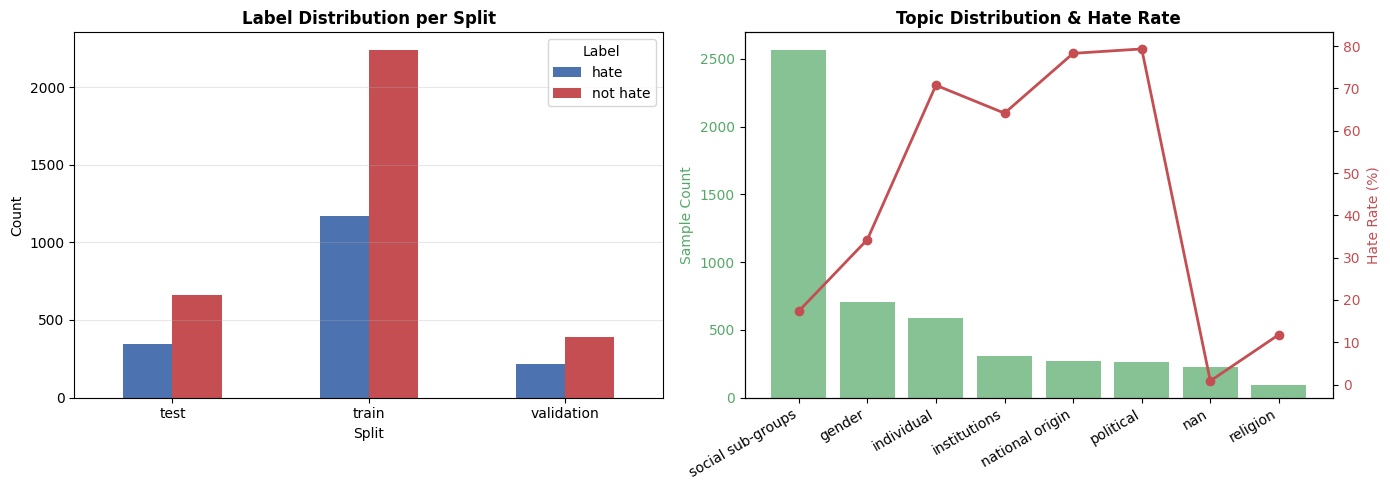

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Label distribution per split
labels_split = df_raw.groupby("split")["hate_final"].value_counts().unstack(fill_value=0)
labels_split.plot(kind="bar", ax=axes[0], stacked=False, color=["#4C72B0", "#C44E52"])
axes[0].set_title("Label Distribution per Split", fontsize=12, fontweight="bold")
axes[0].set_ylabel("Count"); axes[0].set_xlabel("Split")
axes[0].legend(title="Label"); axes[0].grid(axis="y", alpha=0.3)
axes[0].tick_params(axis="x", rotation=0)

# Topic distribution + hate rate
topic_stats = df_raw.groupby(df_raw["topic"].apply(lambda x: str(x).split(",")[0].strip().lower())).agg(
    n=("hate_final", "size"),
    hate_rate=("hate_final", lambda x: (x == "hate").mean())
).sort_values("n", ascending=False)
ax2 = axes[1]
ax2.bar(range(len(topic_stats)), topic_stats["n"], color="#55A868", alpha=0.7, label="Count")
ax2.set_xticks(range(len(topic_stats)))
ax2.set_xticklabels(topic_stats.index, rotation=30, ha="right")
ax2.set_ylabel("Sample Count", color="#55A868")
ax2.tick_params(axis="y", labelcolor="#55A868")
ax3 = ax2.twinx()
ax3.plot(range(len(topic_stats)), topic_stats["hate_rate"]*100, "o-", color="#C44E52", linewidth=2, label="Hate Rate %")
ax3.set_ylabel("Hate Rate (%)", color="#C44E52"); ax3.tick_params(axis="y", labelcolor="#C44E52")
ax2.set_title("Topic Distribution & Hate Rate", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.savefig(DIRS["figures"] / "fig01_label_topic_distribution.png", dpi=120, bbox_inches="tight")
plt.show()

## EDA Figure 2: Text Length Distribution

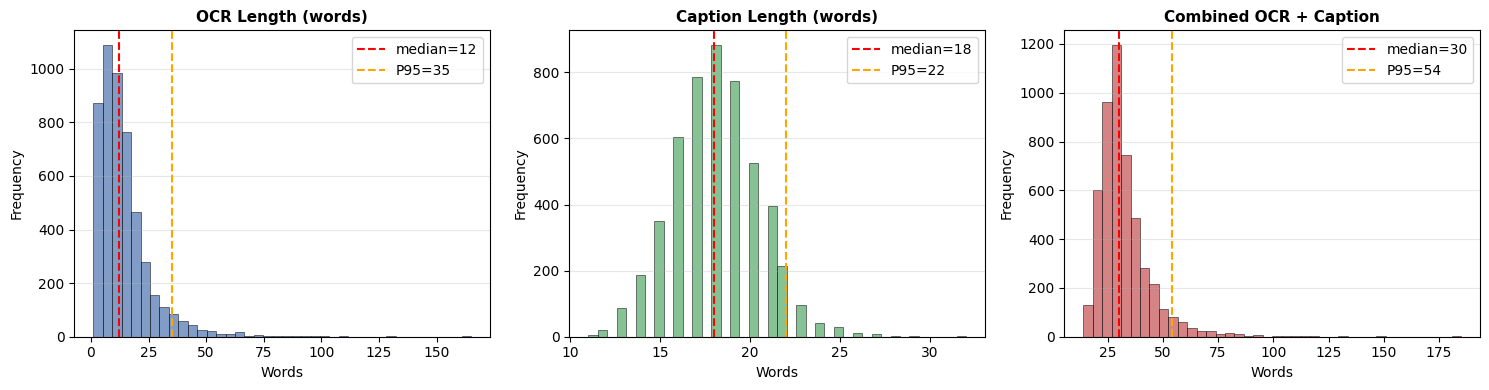

Combined length stats: median=30, P95=54, max_seq_len=128 (truncation safe)


In [7]:
df_raw["ocr_len"]      = df_raw["ocr"].fillna("").str.split().str.len()
df_raw["caption_len"]  = df_raw["caption"].fillna("").str.split().str.len()
df_raw["combined_len"] = df_raw["ocr_len"] + df_raw["caption_len"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for i, (col, title, color) in enumerate([
    ("ocr_len", "OCR Length (words)", "#4C72B0"),
    ("caption_len", "Caption Length (words)", "#55A868"),
    ("combined_len", "Combined OCR + Caption", "#C44E52")
]):
    axes[i].hist(df_raw[col], bins=40, color=color, alpha=0.7, edgecolor="black", linewidth=0.5)
    axes[i].axvline(df_raw[col].median(), color="red", linestyle="--", label=f"median={df_raw[col].median():.0f}")
    axes[i].axvline(df_raw[col].quantile(0.95), color="orange", linestyle="--", label=f"P95={df_raw[col].quantile(0.95):.0f}")
    axes[i].set_title(title, fontsize=11, fontweight="bold")
    axes[i].set_xlabel("Words"); axes[i].set_ylabel("Frequency")
    axes[i].legend(); axes[i].grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(DIRS["figures"] / "fig02_text_length.png", dpi=120, bbox_inches="tight")
plt.show()

print(f"Combined length stats: median={df_raw['combined_len'].median():.0f}, "
      f"P95={df_raw['combined_len'].quantile(0.95):.0f}, "
      f"max_seq_len={CONFIG['max_seq_len']} (truncation safe)")

## Save EDA Summary

In [8]:
eda_summary = {
    "total_samples":      len(df_raw),
    "splits":             df_raw["split"].value_counts().to_dict(),
    "hate_distribution":  df_raw["hate_final"].value_counts(normalize=True).round(4).to_dict(),
    "class_imbalance":    float((df_raw["hate_final"] == "not hate").sum() / max(1, (df_raw["hate_final"] == "hate").sum())),
    "topic_hate_rate":    {t: float(rate) for t, rate in topic_stats["hate_rate"].items()},
    "ocr_stats":          {"median": int(df_raw["ocr_len"].median()), "p95": int(df_raw["ocr_len"].quantile(0.95))},
    "caption_stats":      {"median": int(df_raw["caption_len"].median()), "p95": int(df_raw["caption_len"].quantile(0.95))},
    "combined_stats":     {"median": int(df_raw["combined_len"].median()), "p95": int(df_raw["combined_len"].quantile(0.95))},
}
with open(DIRS["results"] / "eda_summary.json", "w") as f:
    json.dump(eda_summary, f, indent=2)
print("EDA summary saved.")

EDA summary saved.


# PREPROCESSING

## Slang Dictionary (diperluas)

In [9]:
SLANG_DICT = {
    "gw":"saya","gue":"saya","gua":"saya","guwe":"saya","aq":"aku","akoh":"aku","akuh":"aku",
    "lu":"kamu","lo":"kamu","loe":"kamu","elo":"kamu","elu":"kamu","kmu":"kamu","kamuh":"kamu",
    "ane":"saya","ente":"kamu","agan":"kamu","sis":"kakak","bro":"kawan","bray":"kawan","bre":"kawan","cuy":"kawan","klian":"kalian",
    "gak":"tidak","ga":"tidak","gk":"tidak","nggak":"tidak","ngga":"tidak","ngk":"tidak","kgk":"tidak","tdk":"tidak","engga":"tidak","enggak":"tidak","kga":"tidak",
    "yg":"yang","dgn":"dengan","dg":"dengan","krn":"karena","krna":"karena","utk":"untuk","tp":"tapi","tpi":"tapi",
    "klo":"kalau","klau":"kalau","kl":"kalau","klu":"kalau","spy":"supaya","ato":"atau",
    "bgt":"banget","bgtt":"banget","bngt":"banget","bnr":"benar","bener":"benar",
    "emg":"memang","emang":"memang","mmg":"memang","skrg":"sekarang","skrng":"sekarang",
    "td":"tadi","tdi":"tadi","bsk":"besok","knp":"kenapa","gmn":"bagaimana","gimana":"bagaimana","gmana":"bagaimana",
    "kyk":"seperti","kayak":"seperti","kek":"seperti",
    "udh":"sudah","udah":"sudah","uda":"sudah","dah":"sudah","blm":"belum","blom":"belum",
    "lg":"lagi","lgi":"lagi","msh":"masih","msi":"masih","jd":"jadi","jdi":"jadi",
    "tau":"tahu","taw":"tahu","tw":"tahu","liat":"lihat","ngeliat":"melihat","denger":"dengar",
    "ngomong":"bicara","blng":"bilang","bilg":"bilang",
    "aja":"saja","doang":"saja","doank":"saja","sih":"","deh":"","dong":"","kok":"","lah":"","loh":"","lho":"","yah":"",
    "iy":"iya","iyaa":"iya","iye":"iya","yup":"iya","yoi":"iya",
    "org":"orang","orng":"orang","orgnya":"orangnya","dr":"dari","dri":"dari","kpd":"kepada","thd":"terhadap","ttg":"tentang",
    "abis":"habis","trs":"terus","trus":"terus","tmn":"teman","temen":"teman","tman":"teman",
    "rmh":"rumah","kntr":"kantor","krj":"kerja","ank":"anak","indo":"indonesia",
    "cwo":"cowok","cwe":"cewek","cwok":"cowok","cwek":"cewek",
    "wkwk":"haha","wkwkwk":"haha","wkwkwkwk":"haha","wkwkwkwkwk":"haha","hahaha":"haha","hahahaha":"haha","hehehe":"hehe","hehehehe":"hehe",
    "anjir":"anjing","anjay":"anjing","anjrit":"anjing","anjr":"anjing","anying":"anjing","njir":"anjing",
    "bgsd":"bangsat","bgst":"bangsat","bjir":"anjing","bjg":"bajingan","kntl":"kontol","mmk":"memek","tai":"tahi",
}
print(f"Slang dict: {len(SLANG_DICT)} entries")

Slang dict: 149 entries


##  Cleaning Functions

In [10]:
URL_PATTERN     = re.compile(r"(https?://\S+|www\.\S+|\S+\.(?:com|co\.id|net|org|id|tv|me)\b\S*)", re.IGNORECASE)
MENTION_PATTERN = re.compile(r"@\w+")
HASHTAG_PATTERN = re.compile(r"#(\w+)")
ALLOWED_PUNCT   = re.compile(r"[^\w\s\.,!?\-'\"]+", re.UNICODE)
MULTI_SPACE     = re.compile(r"\s+")
SEP_TOKEN = "[SEP]"

def _norm_unicode(t): return unicodedata.normalize("NFKC", t)

def _norm_slang(text, slang=SLANG_DICT):
    out = []
    for tok in text.split():
        prefix, suffix, core = "", "", tok
        while core and not core[0].isalnum(): prefix += core[0]; core = core[1:]
        while core and not core[-1].isalnum(): suffix = core[-1] + suffix; core = core[:-1]
        out.append(f"{prefix}{slang.get(core.lower(), core)}{suffix}")
    return " ".join(out)

def clean_ocr(text):
    if text is None: return ""
    if isinstance(text, float) and pd.isna(text): return ""
    text = _norm_unicode(str(text)).lower()
    text = URL_PATTERN.sub(" ", text); text = MENTION_PATTERN.sub(" ", text)
    text = HASHTAG_PATTERN.sub(r"\1", text); text = ALLOWED_PUNCT.sub(" ", text)
    text = _norm_slang(text)
    return MULTI_SPACE.sub(" ", text).strip()

def _safe_str(x):
    if x is None: return ""
    if isinstance(x, float) and pd.isna(x): return ""
    return str(x).strip()

def format_input(topic, caption, ocr_cleaned, sep=SEP_TOKEN, with_topic=True):
    if not with_topic:
        return f"{_safe_str(caption)} {sep} {_safe_str(ocr_cleaned)}".strip()
    if topic is None or (isinstance(topic, float) and pd.isna(topic)):
        topic_str = "unknown"
    elif isinstance(topic, (list, tuple, set)):
        items = sorted({str(t).lower().strip() for t in topic if t})
        topic_str = ",".join(items) if items else "unknown"
    else:
        topic_str = str(topic).lower().strip() or "unknown"
    return f"[{topic_str}] {_safe_str(caption)} {sep} {_safe_str(ocr_cleaned)}".strip()

## Topic Multi-Hot

In [11]:
TOPIC_LIST = ["political","national origin","individual","institutions",
              "gender","religion","social sub-groups","unknown"]
TOPIC2IDX = {t: i for i, t in enumerate(TOPIC_LIST)}
N_TOPICS  = len(TOPIC_LIST)

def topic_to_multihot(topic):
    vec = np.zeros(N_TOPICS, dtype=np.float32)
    if topic is None or (isinstance(topic, float) and pd.isna(topic)):
        vec[TOPIC2IDX["unknown"]] = 1.0; return vec
    parts = [p.strip().lower() for p in str(topic).split(",") if p.strip()]
    found = False
    for p in parts:
        if p in TOPIC2IDX: vec[TOPIC2IDX[p]] = 1.0; found = True
    if not found: vec[TOPIC2IDX["unknown"]] = 1.0
    return vec

## Apply Preprocessing

In [12]:
df = df_raw.copy()
df["label"]       = df["hate_final"].map({"not hate": 0, "hate": 1})
df["ocr_cleaned"] = df["ocr"].apply(clean_ocr)
df["text_input"]  = df.apply(lambda r: format_input(r["topic"], r["caption"], r["ocr_cleaned"], with_topic=True), axis=1)
df["text_input_no_topic"] = df.apply(lambda r: format_input(r["topic"], r["caption"], r["ocr_cleaned"], with_topic=False), axis=1)
df["topic_multihot"] = df["topic"].apply(topic_to_multihot)

def resolve_image_path(row):
    raw = row.get("local_image_path") or row.get("image_path")
    if raw is None or (isinstance(raw, float) and pd.isna(raw)): return None
    fname = Path(str(raw).replace("\\","/")).name
    return str(IMG_DIR / row["split"] / fname)
df["full_image_path"] = df.apply(resolve_image_path, axis=1)

df_train = df[df["split"] == "train"].copy().reset_index(drop=True)
df_val   = (df[df["split"] == "validation"] if "validation" in df["split"].unique() else df[df["split"] == "val"]).copy().reset_index(drop=True)
df_test  = df[df["split"] == "test"].copy().reset_index(drop=True)
print(f"Train: {len(df_train)}  Val: {len(df_val)}  Test: {len(df_test)}")
print(f"Sample text input:\n  {df_train.iloc[0]['text_input'][:150]}")
print(f"Sample no-topic:\n  {df_train.iloc[0]['text_input_no_topic'][:150]}")

Train: 3415  Val: 603  Test: 1005
Sample text input:
  [social sub-groups] Gambar ini secara humoris menggambarkan fenomena tetangga yang menguping perselisihan rumah tangga, dilambangkan oleh kucing denga
Sample no-topic:
  Gambar ini secara humoris menggambarkan fenomena tetangga yang menguping perselisihan rumah tangga, dilambangkan oleh kucing dengan telinga menonjol. 


## Tokenizer + Image Transforms 

In [13]:
tokenizer = AutoTokenizer.from_pretrained(CONFIG["text_model_name"])
img_proc  = ViTImageProcessor.from_pretrained(CONFIG["image_model_name"])
IMG_MEAN, IMG_STD = img_proc.image_mean, img_proc.image_std

# AUGMENTASI: HAPUS horizontal flip (terbukti harmful di V1). Pertahankan augmentasi yang aman.
TRAIN_TF = transforms.Compose([
    transforms.Resize((CONFIG["img_size"], CONFIG["img_size"])),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.RandomGrayscale(p=0.1),
    transforms.RandomPerspective(distortion_scale=0.1, p=0.2),
    transforms.RandomAffine(degrees=5, translate=(0.05, 0.05)),  # NEW: small affine, content-preserving
    transforms.ToTensor(),
    transforms.Normalize(mean=IMG_MEAN, std=IMG_STD),
])
EVAL_TF = transforms.Compose([
    transforms.Resize((CONFIG["img_size"], CONFIG["img_size"])),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMG_MEAN, std=IMG_STD),
])
print(f"Tokenizer: {CONFIG['text_model_name']}, max_len={CONFIG['max_seq_len']}")
print(f"Image: size={CONFIG['img_size']}, mean={IMG_MEAN}, std={IMG_STD}")

config.json: 0.00B [00:00, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/160 [00:00<?, ?B/s]

Tokenizer: indolem/indobertweet-base-uncased, max_len=128
Image: size=224, mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5]


## Dataset Class

In [14]:
class IndoMemeDataset(Dataset):
    def __init__(self, df_split, tokenizer, transform, max_seq_len=128, with_topic=True):
        self.df = df_split.reset_index(drop=True)
        self.tokenizer = tokenizer
        self.transform = transform
        self.max_seq_len = max_seq_len
        self.text_col = "text_input" if with_topic else "text_input_no_topic"

    def __len__(self): return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img = Image.open(row["full_image_path"]).convert("RGB")
        img_tensor = self.transform(img)
        enc = self.tokenizer(row[self.text_col], padding="max_length", truncation=True,
                             max_length=self.max_seq_len, return_tensors="pt")
        return {
            "input_ids":      enc["input_ids"].squeeze(0),
            "attention_mask": enc["attention_mask"].squeeze(0),
            "pixel_values":   img_tensor,
            "topic":          torch.from_numpy(row["topic_multihot"]),
            "label":          torch.tensor(int(row["label"]), dtype=torch.long),
            "idx":            int(row["idx"]),
        }
print("Dataset class defined.")

Dataset class defined.


# MODEL DEFINITIONS (4 VARIANTS) 

## Shared Components (encoders + freeze + heads)

In [15]:
def _freeze_bottom(layers, n):
    for i, layer in enumerate(layers):
        if i < n:
            for p in layer.parameters(): p.requires_grad = False

class SharedBackbone(nn.Module):
    """Text + Image encoder dengan freeze policy V2 (bottom 2 layer)."""
    def __init__(self, cfg, image_attn_impl="sdpa"):
        super().__init__()
        self.text_encoder  = AutoModel.from_pretrained(cfg["text_model_name"])
        self.image_encoder = ViTModel.from_pretrained(cfg["image_model_name"], attn_implementation=image_attn_impl)
        _freeze_bottom(self.text_encoder.encoder.layer,  cfg["freeze_n_layers"])
        _freeze_bottom(self.image_encoder.encoder.layer, cfg["freeze_n_layers"])
        for p in self.text_encoder.embeddings.parameters():  p.requires_grad = False
        for p in self.image_encoder.embeddings.parameters(): p.requires_grad = False

    def encode(self, input_ids, attention_mask, pixel_values, output_attentions=False):
        t = self.text_encoder(input_ids=input_ids, attention_mask=attention_mask)
        i = self.image_encoder(pixel_values=pixel_values, output_attentions=output_attentions)
        return t.last_hidden_state, i.last_hidden_state, (i.attentions if output_attentions else None)


def make_supcon_head(cfg, hidden):
    return nn.Sequential(
        nn.Linear(hidden, cfg["supcon_proj_hidden"]), nn.ReLU(),
        nn.Linear(cfg["supcon_proj_hidden"], cfg["supcon_proj_out"]),
    )

def make_topic_proj(cfg):
    return nn.Sequential(nn.Linear(N_TOPICS, cfg["topic_emb_dim"]), nn.GELU())

def make_head(cfg, in_dim):
    return nn.Sequential(
        nn.Linear(in_dim, cfg["head_hidden"]), nn.GELU(),
        nn.Dropout(cfg["head_dropout"]),
        nn.Linear(cfg["head_hidden"], 2),
    )

## Varian A: Late Fusion (Pamungkas baseline)

In [16]:
class VariantA_LateFusion(nn.Module):
    """Concat CLS_text + CLS_image + topic_emb -> head."""
    NAME = "A_late_fusion"; USE_TOPIC = True
    def __init__(self, cfg):
        super().__init__()
        self.backbone = SharedBackbone(cfg)
        h = self.backbone.text_encoder.config.hidden_size
        self.supcon_proj = make_supcon_head(cfg, 2*h)            # supcon dari concat CLS
        self.topic_proj  = make_topic_proj(cfg)
        self.head        = make_head(cfg, 2*h + cfg["topic_emb_dim"])

    def forward(self, input_ids, attention_mask, pixel_values, topic):
        th, ih, _ = self.backbone.encode(input_ids, attention_mask, pixel_values)
        cls_text, cls_image = th[:, 0], ih[:, 0]
        fused = torch.cat([cls_text, cls_image], dim=-1)        # [B, 2H]
        supcon_feats = F.normalize(self.supcon_proj(fused), dim=-1)
        topic_emb = self.topic_proj(topic)
        logits = self.head(torch.cat([fused, topic_emb], dim=-1))
        return {"logits": logits, "supcon_features": supcon_feats, "fused": fused, "g1": 0.0, "g2": 0.0}

## Varian B: Single Cross-Attention (UTAMA)

In [17]:
class VariantB_SingleCrossAttn(nn.Module):
    """
    UTAMA. Text-as-query attends image patches.
    h_text (B,T,H) + h_image (B,P,H) -> 1 layer cross-attn -> pool -> concat topic -> head.

    Dropout di output cross-attn (mitigasi overfit). save_attn flag utk XAI extract.
    """
    NAME = "B_single_cross_attn"; USE_TOPIC = True
    def __init__(self, cfg, with_topic=True):
        super().__init__()
        self.with_topic = with_topic
        self.backbone = SharedBackbone(cfg)
        h = self.backbone.text_encoder.config.hidden_size

        self.cross_attn = nn.MultiheadAttention(h, cfg["icam_num_heads"],
                                                 dropout=cfg["cross_attn_dropout"], batch_first=True)
        self.attn_dropout = nn.Dropout(cfg["cross_attn_dropout"])
        self.layer_norm   = nn.LayerNorm(h)
        self.fusion_proj  = nn.Linear(2 * h, h)                 # concat (h_text_cls, attended_img) -> h

        self.supcon_proj = make_supcon_head(cfg, h)
        if with_topic:
            self.topic_proj = make_topic_proj(cfg)
            head_in = h + cfg["topic_emb_dim"]
        else:
            self.topic_proj = None
            head_in = h
        self.head = make_head(cfg, head_in)

        self.save_attn = False
        self.last_attn = None

    def forward(self, input_ids, attention_mask, pixel_values, topic):
        th, ih, _ = self.backbone.encode(input_ids, attention_mask, pixel_values)
        # Cross-attention: text Q, image K/V
        attn_out, attn_w = self.cross_attn(
            query=th, key=ih, value=ih,
            key_padding_mask=None,
            need_weights=self.save_attn, average_attn_weights=True,
        )
        attn_out = self.attn_dropout(attn_out)
        # Pool text-side: gunakan posisi CLS (text[:, 0]) yang sekarang sudah image-aware via attn
        cls_text_aware = attn_out[:, 0]                          # [B, H]
        cls_text       = th[:, 0]                                # [B, H]
        fused          = self.layer_norm(self.fusion_proj(torch.cat([cls_text, cls_text_aware], dim=-1)))

        supcon_feats = F.normalize(self.supcon_proj(fused), dim=-1)

        if self.with_topic:
            topic_emb = self.topic_proj(topic)
            logits = self.head(torch.cat([fused, topic_emb], dim=-1))
        else:
            logits = self.head(fused)

        if self.save_attn and attn_w is not None:
            self.last_attn = attn_w.detach()                     # [B, T, P]

        return {"logits": logits, "supcon_features": supcon_feats, "fused": fused, "g1": 0.0, "g2": 0.0}

## Varian C: ICAM Three-Stream (ablasi, dari V1)

In [18]:
class VariantC_ICAM(nn.Module):
    """ICAM lama: 2 cross-attn + complementary stream + dual gating. Untuk ablasi."""
    NAME = "C_icam_three_stream"; USE_TOPIC = True
    def __init__(self, cfg):
        super().__init__()
        self.backbone = SharedBackbone(cfg)
        h = self.backbone.text_encoder.config.hidden_size
        self.t2i_attn = nn.MultiheadAttention(h, cfg["icam_num_heads"], dropout=cfg["cross_attn_dropout"], batch_first=True)
        self.i2t_attn = nn.MultiheadAttention(h, cfg["icam_num_heads"], dropout=cfg["cross_attn_dropout"], batch_first=True)
        self.gate_relevant    = nn.Linear(2*h, h)
        self.gate_incongruent = nn.Linear(2*h, h)
        self.fusion_proj = nn.Linear(h, h)
        self.layer_norm  = nn.LayerNorm(h)
        self.supcon_proj = make_supcon_head(cfg, h)
        self.topic_proj  = make_topic_proj(cfg)
        self.head        = make_head(cfg, h + cfg["topic_emb_dim"])
        self.save_attn = False
        self.last_t2i_attn = self.last_incongruity = None

    def forward(self, input_ids, attention_mask, pixel_values, topic):
        th, ih, _ = self.backbone.encode(input_ids, attention_mask, pixel_values)
        text_kpm = ~attention_mask.bool()
        t2i_out, t2i_w = self.t2i_attn(th, ih, ih, key_padding_mask=None,
                                        need_weights=self.save_attn, average_attn_weights=True)
        i2t_out, _    = self.i2t_attn(ih, th, th, key_padding_mask=text_kpm,
                                       need_weights=False, average_attn_weights=True)
        h_image_pooled = i2t_out.mean(dim=1)
        # Stream 3 incongruity
        tn, ino = F.normalize(th, dim=-1), F.normalize(ih, dim=-1)
        sim = torch.bmm(tn, ino.transpose(1, 2))
        incongruity = 1.0 - sim.abs()
        inc_w = F.softmax(incongruity, dim=-1)
        h_inc = torch.bmm(inc_w, ih)
        m = attention_mask.unsqueeze(-1).float()
        h_inc_pooled = (h_inc * m).sum(dim=1) / m.sum(dim=1).clamp(min=1.0)
        h_text = th[:, 0]
        g1 = torch.sigmoid(self.gate_relevant(torch.cat([h_text, h_image_pooled], dim=-1)))
        g2 = torch.sigmoid(self.gate_incongruent(torch.cat([h_text, h_inc_pooled], dim=-1)))
        fused_raw = h_text + g1 * h_image_pooled + g2 * h_inc_pooled
        fused = self.layer_norm(self.fusion_proj(fused_raw))
        supcon_feats = F.normalize(self.supcon_proj(fused), dim=-1)
        topic_emb = self.topic_proj(topic)
        logits = self.head(torch.cat([fused, topic_emb], dim=-1))
        if self.save_attn:
            self.last_t2i_attn    = t2i_w.detach() if t2i_w is not None else None
            self.last_incongruity = incongruity.detach()
        return {"logits": logits, "supcon_features": supcon_feats, "fused": fused,
                "g1": g1.mean().item(), "g2": g2.mean().item()}

## Variant Builder & Param Count

In [19]:
def build_variant(name, cfg):
    if name == "A_late_fusion":
        return VariantA_LateFusion(cfg)
    if name == "B_single_cross_attn":
        return VariantB_SingleCrossAttn(cfg, with_topic=True)
    if name == "C_icam_three_stream":
        return VariantC_ICAM(cfg)
    if name == "D_no_topic":
        return VariantB_SingleCrossAttn(cfg, with_topic=False)
    raise ValueError(name)

# Print param summary semua varian
print(f"{'Variant':<25} {'Total (M)':<12} {'Trainable (M)':<15} {'%':<8}")
print("-" * 60)
for v in CONFIG["ablation_variants"]:
    m = build_variant(v, CONFIG)
    n_total = sum(p.numel() for p in m.parameters())
    n_train = sum(p.numel() for p in m.parameters() if p.requires_grad)
    print(f"{v:<25} {n_total/1e6:<12.2f} {n_train/1e6:<15.2f} {n_train/n_total*100:<8.1f}")
    del m; gc.collect(); torch.cuda.empty_cache()

Variant                   Total (M)    Trainable (M)   %       
------------------------------------------------------------


pytorch_model.bin:   0%|          | 0.00/445M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: indolem/indobertweet-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


model.safetensors:   0%|          | 0.00/445M [00:00<?, ?B/s]

config.json:   0%|          | 0.00/502 [00:00<?, ?B/s]

... (11 outputs left out)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: indolem/indobertweet-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

D_no_topic                200.80       146.80          73.1    


# TRAINING INFRASTRUCTURE 

## Loss Functions (Focal + SupCon + R-Drop)

In [20]:
class FocalLoss(nn.Module):
    def __init__(self, gamma=2.0, alpha=None, label_smoothing=0.0, num_classes=2):
        super().__init__()
        self.gamma, self.label_smoothing, self.num_classes = gamma, label_smoothing, num_classes
        if alpha is not None:
            self.register_buffer("alpha", torch.tensor(alpha, dtype=torch.float32))
        else:
            self.alpha = None
    def forward(self, logits, target):
        log_probs = F.log_softmax(logits, dim=-1); probs = log_probs.exp()
        with torch.no_grad():
            true_dist = torch.full_like(log_probs, self.label_smoothing / (self.num_classes - 1))
            true_dist.scatter_(1, target.unsqueeze(1), 1.0 - self.label_smoothing)
        pt = probs.gather(1, target.unsqueeze(1)).squeeze(1).clamp(min=1e-8)
        focal_w = (1.0 - pt) ** self.gamma
        ce = -(true_dist * log_probs).sum(dim=-1)
        loss = focal_w * ce
        if self.alpha is not None:
            loss = self.alpha.to(logits.device)[target] * loss
        return loss.mean()

class SupConLoss(nn.Module):
    def __init__(self, temperature=0.07):
        super().__init__(); self.temperature = temperature
    def forward(self, features, labels):
        device = features.device; B = features.size(0)
        sim = torch.matmul(features, features.T) / self.temperature
        sim_max, _ = sim.max(dim=1, keepdim=True)
        sim = sim - sim_max.detach()
        labels = labels.contiguous().view(-1, 1)
        mask_pos = (labels == labels.T).float().to(device)
        eye = torch.eye(B, device=device); mask_pos = mask_pos - eye
        mask_all = 1.0 - eye
        exp_sim = torch.exp(sim) * mask_all
        log_prob = sim - torch.log(exp_sim.sum(dim=1, keepdim=True) + 1e-12)
        n_pos = mask_pos.sum(dim=1)
        mean_log = (mask_pos * log_prob).sum(dim=1) / n_pos.clamp(min=1.0)
        valid = (n_pos > 0).float()
        return -(mean_log * valid).sum() / valid.sum().clamp(min=1.0)

def rdrop_kl_loss(logits1, logits2):
    """Symmetric KL divergence between two forward passes."""
    p1 = F.log_softmax(logits1, dim=-1); p2 = F.log_softmax(logits2, dim=-1)
    q1 = F.softmax(logits1, dim=-1);     q2 = F.softmax(logits2, dim=-1)
    kl = 0.5 * (F.kl_div(p1, q2, reduction="batchmean") + F.kl_div(p2, q1, reduction="batchmean"))
    return kl

print("Losses ready: Focal, SupCon, R-Drop KL")

Losses ready: Focal, SupCon, R-Drop KL


## Optimizer & Scheduler Builder

In [21]:
def build_optim_sched(model, cfg, num_training_steps):
    enc_p, fusion_p, head_p = [], [], []
    for n, p in model.named_parameters():
        if not p.requires_grad: continue
        if "backbone" in n or n.startswith("text_encoder") or n.startswith("image_encoder"):
            enc_p.append(p)
        elif any(k in n for k in ["cross_attn", "t2i_attn", "i2t_attn", "gate_", "fusion_proj", "layer_norm"]):
            fusion_p.append(p)
        else:
            head_p.append(p)
    groups = [
        {"params": enc_p,    "lr": cfg["lr_encoder"], "weight_decay": cfg["weight_decay"]},
        {"params": fusion_p, "lr": cfg["lr_fusion"],  "weight_decay": cfg["weight_decay"]},
        {"params": head_p,   "lr": cfg["lr_head"],    "weight_decay": cfg["weight_decay"]},
    ]
    optimizer = torch.optim.AdamW(groups)
    num_warmup = int(cfg["warmup_ratio"] * num_training_steps)
    if cfg["scheduler_type"] == "cosine":
        scheduler = get_cosine_schedule_with_warmup(optimizer, num_warmup, num_training_steps)
    else:
        scheduler = get_linear_schedule_with_warmup(optimizer, num_warmup, num_training_steps)
    return optimizer, scheduler

##  Train One Epoch (with R-Drop + curriculum SupCon)

In [22]:
def train_one_epoch(model, loader, optimizer, scheduler, focal_fn, supcon_fn, scaler, cfg, epoch):
    model.train()
    total_focal = total_supcon = total_rdrop = 0.0; n = 0
    g1_log, g2_log = [], []
    supcon_active = epoch > cfg["supcon_warmup_epochs"]
    rdrop_active  = cfg["rdrop_alpha"] > 0
    optimizer.zero_grad()
    pbar = tqdm(loader, desc=f"ep{epoch:02d} {'F+S' if supcon_active else 'F  '}{'+R' if rdrop_active else ''}", leave=False)
    for step, batch in enumerate(pbar):
        ids   = batch["input_ids"].to(DEVICE, non_blocking=True)
        mask  = batch["attention_mask"].to(DEVICE, non_blocking=True)
        pix   = batch["pixel_values"].to(DEVICE, non_blocking=True)
        topic = batch["topic"].to(DEVICE, non_blocking=True)
        lab   = batch["label"].to(DEVICE, non_blocking=True)

        with autocast(device_type="cuda"):
            out1 = model(ids, mask, pix, topic)
            L_focal = focal_fn(out1["logits"], lab)

            if rdrop_active:
                out2 = model(ids, mask, pix, topic)             # second pass dgn dropout berbeda
                L_focal2 = focal_fn(out2["logits"], lab)
                L_focal_total = 0.5 * (L_focal + L_focal2)
                L_rdrop = rdrop_kl_loss(out1["logits"], out2["logits"])
            else:
                L_focal_total = L_focal
                L_rdrop = torch.tensor(0.0, device=DEVICE)

            if supcon_active:
                L_supcon = supcon_fn(out1["supcon_features"], lab)
                if rdrop_active:
                    L_supcon = 0.5 * (L_supcon + supcon_fn(out2["supcon_features"], lab))
            else:
                L_supcon = torch.tensor(0.0, device=DEVICE)

            loss_total = L_focal_total + cfg["supcon_lambda"] * L_supcon + cfg["rdrop_alpha"] * L_rdrop
            loss = loss_total / cfg["grad_accum"]

        scaler.scale(loss).backward()
        bs = lab.size(0)
        total_focal  += L_focal_total.item() * bs
        total_supcon += L_supcon.item() * bs
        total_rdrop  += L_rdrop.item() * bs
        n += bs
        g1_log.append(out1.get("g1", 0.0)); g2_log.append(out1.get("g2", 0.0))
        if (step + 1) % cfg["grad_accum"] == 0:
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_([p for p in model.parameters() if p.requires_grad], cfg["grad_clip"])
            scaler.step(optimizer); scaler.update(); scheduler.step()
            optimizer.zero_grad()
        pbar.set_postfix(focal=f"{L_focal_total.item():.3f}",
                          supcon=f"{L_supcon.item():.3f}",
                          rdrop=f"{L_rdrop.item():.3f}")
    return (total_focal/max(n,1), total_supcon/max(n,1), total_rdrop/max(n,1),
            float(np.mean(g1_log)), float(np.mean(g2_log)))

## Evaluate

In [23]:
@torch.no_grad()
def evaluate(model, loader, threshold=0.5):
    model.eval()
    all_logits, all_labels = [], []
    for batch in loader:
        ids   = batch["input_ids"].to(DEVICE)
        mask  = batch["attention_mask"].to(DEVICE)
        pix   = batch["pixel_values"].to(DEVICE)
        topic = batch["topic"].to(DEVICE)
        with autocast(device_type="cuda"):
            out = model(ids, mask, pix, topic)
        all_logits.append(out["logits"].float().cpu()); all_labels.append(batch["label"])
    logits = torch.cat(all_logits); labels = torch.cat(all_labels).numpy()
    probs = F.softmax(logits, dim=-1).numpy()
    prob_hate = probs[:, 1]
    preds = (prob_hate >= threshold).astype(int)
    p, r, f, _ = precision_recall_fscore_support(labels, preds, labels=[0,1], zero_division=0)
    out = dict(
        macro_f1   = float(f1_score(labels, preds, average="macro")),
        weighted_f1= float(f1_score(labels, preds, average="weighted")),
        accuracy   = float(accuracy_score(labels, preds)),
        nothate_p=float(p[0]), nothate_r=float(r[0]), nothate_f1=float(f[0]),
        hate_p=float(p[1]),    hate_r=float(r[1]),    hate_f1=float(f[1]),
        threshold=float(threshold),
    )
    if len(set(labels)) > 1: out["roc_auc"] = float(roc_auc_score(labels, prob_hate))
    return out, prob_hate, labels


def search_threshold(y_true, y_prob_hate, lo, hi, step):
    best = (-1, 0.5)
    for thr in np.arange(lo, hi + 1e-9, step):
        f = f1_score(y_true, (y_prob_hate >= thr).astype(int), average="macro")
        if f > best[0]:
            best = (f, float(thr))
    return best

## Build Loaders

In [24]:
def build_loaders(seed, with_topic=True, train_aug=True):
    set_seed(seed)
    ds_train = IndoMemeDataset(df_train, tokenizer, TRAIN_TF if train_aug else EVAL_TF,
                                CONFIG["max_seq_len"], with_topic=with_topic)
    ds_val   = IndoMemeDataset(df_val,   tokenizer, EVAL_TF, CONFIG["max_seq_len"], with_topic=with_topic)
    ds_test  = IndoMemeDataset(df_test,  tokenizer, EVAL_TF, CONFIG["max_seq_len"], with_topic=with_topic)
    labels_train = df_train["label"].values
    cc = np.bincount(labels_train, minlength=2)
    sw = 1.0 / cc[labels_train]
    g = torch.Generator(); g.manual_seed(seed)
    sampler = WeightedRandomSampler(weights=torch.from_numpy(sw).double(),
                                     num_samples=len(sw), replacement=True, generator=g)
    dl_train = DataLoader(ds_train, batch_size=CONFIG["batch_size"], sampler=sampler, num_workers=2, pin_memory=True)
    dl_val   = DataLoader(ds_val,   batch_size=CONFIG["batch_size"], shuffle=False, num_workers=2, pin_memory=True)
    dl_test  = DataLoader(ds_test,  batch_size=CONFIG["batch_size"], shuffle=False, num_workers=2, pin_memory=True)
    return dl_train, dl_val, dl_test

## Main Training Driver

In [25]:
def train_model(variant_name, seed, save_dir, force=False):
    """Train one variant for one seed. Returns dict of results. Resume-friendly."""
    tag = f"{variant_name}_seed{seed}"
    ckpt_path = save_dir / f"{tag}.pt"
    result_path = save_dir / f"{tag}_result.json"
    if (not force) and ckpt_path.exists() and result_path.exists():
        with open(result_path) as f: return json.load(f)

    print(f"\n{'='*60}\n{tag}\n{'='*60}")
    set_seed(seed)
    with_topic = (variant_name != "D_no_topic")
    dl_train, dl_val, dl_test = build_loaders(seed, with_topic=with_topic)
    model = build_variant(variant_name, CONFIG).to(DEVICE)
    n_steps = math.ceil(len(dl_train) / CONFIG["grad_accum"]) * CONFIG["num_epochs"]
    optimizer, scheduler = build_optim_sched(model, CONFIG, n_steps)
    scaler = GradScaler("cuda")
    focal_fn = FocalLoss(gamma=CONFIG["focal_gamma"], alpha=CONFIG["class_weights"],
                          label_smoothing=CONFIG["label_smoothing"])
    supcon_fn = SupConLoss(temperature=CONFIG["supcon_temperature"])

    best_val_f1, best_epoch, no_improve = -1.0, 0, 0
    log = []
    t0 = time.time()
    for epoch in range(1, CONFIG["num_epochs"] + 1):
        focal_l, supcon_l, rdrop_l, g1m, g2m = train_one_epoch(
            model, dl_train, optimizer, scheduler, focal_fn, supcon_fn, scaler, CONFIG, epoch)
        val_metrics, _, _ = evaluate(model, dl_val, threshold=0.5)
        log.append(dict(epoch=epoch, focal=focal_l, supcon=supcon_l, rdrop=rdrop_l,
                         g1=g1m, g2=g2m,
                         val_f1=val_metrics["macro_f1"], val_hate_f1=val_metrics["hate_f1"],
                         val_hate_r=val_metrics["hate_r"], val_auc=val_metrics.get("roc_auc", float("nan"))))
        print(f"  ep{epoch:02d} focal={focal_l:.3f} supcon={supcon_l:.3f} rdrop={rdrop_l:.3f} | "
              f"val_F1={val_metrics['macro_f1']:.4f} hate_R={val_metrics['hate_r']:.3f}")
        if val_metrics["macro_f1"] > best_val_f1:
            best_val_f1, best_epoch, no_improve = val_metrics["macro_f1"], epoch, 0
            torch.save({"epoch": epoch, "state_dict": model.state_dict()}, ckpt_path)
        else:
            no_improve += 1
            if no_improve >= CONFIG["early_stop_pat"]:
                print(f"  early stop at ep{epoch}"); break

    pd.DataFrame(log).to_csv(save_dir / f"{tag}_metrics.csv", index=False)

    # Reload best, calibrate threshold, eval test
    ckpt = torch.load(ckpt_path, map_location=DEVICE)
    model.load_state_dict(ckpt["state_dict"])
    val_05, prob_val, y_val = evaluate(model, dl_val, threshold=0.5)
    best_f1_val, best_thr = search_threshold(y_val, prob_val, CONFIG["thr_search_lo"], CONFIG["thr_search_hi"], CONFIG["thr_search_step"])
    test_metrics, prob_test, y_test = evaluate(model, dl_test, threshold=best_thr)

    result = dict(
        variant=variant_name, seed=seed, best_epoch=best_epoch,
        best_threshold=best_thr,
        val_metrics_05=val_05,
        val_f1_at_best_thr=best_f1_val,
        test_metrics=test_metrics,
        elapsed_min=(time.time()-t0)/60,
    )
    with open(result_path, "w") as f: json.dump(result, f, indent=2)
    print(f"  done {tag}: test_F1={test_metrics['macro_f1']:.4f} (thr={best_thr:.2f}, {result['elapsed_min']:.1f}min)")

    del model, optimizer, scheduler, scaler
    torch.cuda.empty_cache(); gc.collect()
    return result

# ABLATION EXPERIMENTS

## Run All Variants × Seeds

In [26]:
ablation_results = {}
for variant in CONFIG["ablation_variants"]:
    ablation_results[variant] = []
    for seed in CONFIG["ablation_seeds"]:
        res = train_model(variant, seed, DIRS["ablation"])
        ablation_results[variant].append(res)
print(f"\n{'='*60}\nALL ABLATION RUNS DONE\n{'='*60}")


ALL ABLATION RUNS DONE


## Aggregate Mean ± Std per Variant

In [27]:
rows = []
for v in CONFIG["ablation_variants"]:
    runs = ablation_results[v]
    for metric_key in ["macro_f1", "hate_p", "hate_r", "hate_f1", "roc_auc"]:
        vals = [r["test_metrics"].get(metric_key, np.nan) for r in runs]
        if all(np.isnan(vals)): continue
    macro_f1s = [r["test_metrics"]["macro_f1"] for r in runs]
    hate_rs   = [r["test_metrics"]["hate_r"]   for r in runs]
    hate_f1s  = [r["test_metrics"]["hate_f1"]  for r in runs]
    aucs      = [r["test_metrics"].get("roc_auc", np.nan) for r in runs]
    rows.append(dict(
        variant=v, n_seeds=len(runs),
        macro_f1_mean=np.mean(macro_f1s), macro_f1_std=np.std(macro_f1s),
        hate_r_mean=np.mean(hate_rs),     hate_r_std=np.std(hate_rs),
        hate_f1_mean=np.mean(hate_f1s),   hate_f1_std=np.std(hate_f1s),
        auc_mean=np.nanmean(aucs),
        threshold_mean=np.mean([r["best_threshold"] for r in runs]),
    ))
df_ablation = pd.DataFrame(rows)
df_ablation.to_csv(DIRS["results"] / "ablation_results.csv", index=False)
print(df_ablation.to_string(index=False, float_format=lambda x: f"{x:.4f}" if isinstance(x, float) else str(x)))

            variant  n_seeds  macro_f1_mean  macro_f1_std  hate_r_mean  hate_r_std  hate_f1_mean  hate_f1_std  auc_mean  threshold_mean
      A_late_fusion        3         0.7912        0.0014       0.7358      0.0211        0.7280       0.0046    0.8827          0.4900
B_single_cross_attn        3         0.7814        0.0047       0.7089      0.0249        0.7129       0.0091    0.8768          0.5000
C_icam_three_stream        3         0.7946        0.0043       0.6993      0.0398        0.7257       0.0112    0.8841          0.5500
         D_no_topic        3         0.7456        0.0040       0.6052      0.0227        0.6538       0.0038    0.8330          0.5100


## Ablation Comparison Figure

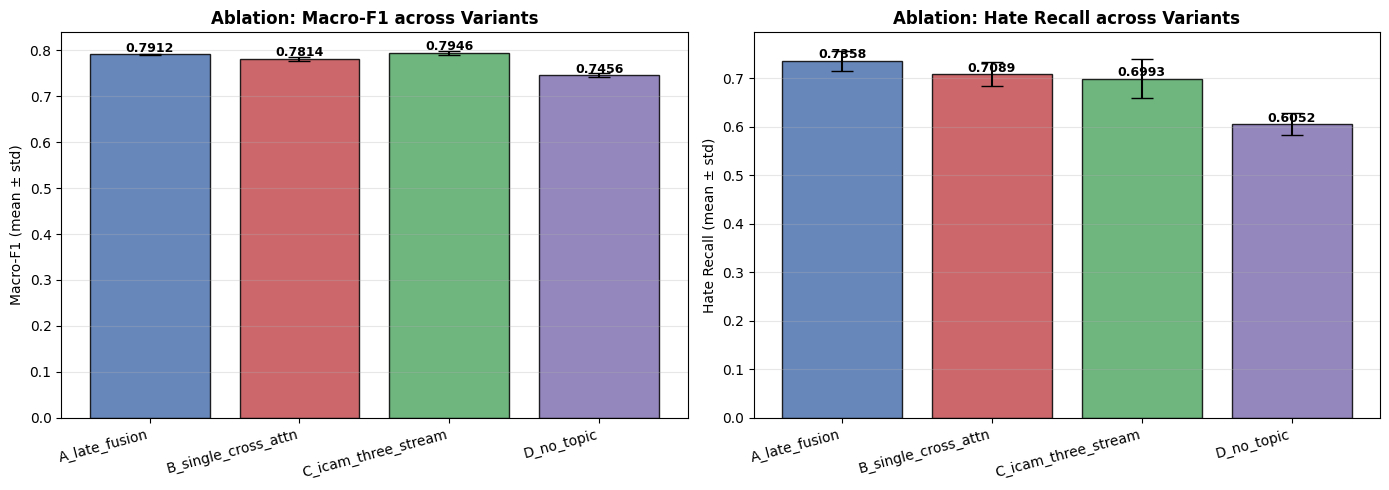

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
xv = df_ablation["variant"].tolist()
xpos = np.arange(len(xv))

# Macro-F1 with error bars
axes[0].bar(xpos, df_ablation["macro_f1_mean"], yerr=df_ablation["macro_f1_std"],
            capsize=8, color=["#4C72B0", "#C44E52", "#55A868", "#8172B2"], alpha=0.85, edgecolor="black")
axes[0].set_xticks(xpos); axes[0].set_xticklabels(xv, rotation=15, ha="right")
axes[0].set_ylabel("Macro-F1 (mean ± std)"); axes[0].set_title("Ablation: Macro-F1 across Variants", fontweight="bold")
axes[0].grid(axis="y", alpha=0.3)
for i, v in enumerate(df_ablation["macro_f1_mean"]):
    axes[0].text(i, v + 0.005, f"{v:.4f}", ha="center", fontsize=9, fontweight="bold")

# Hate Recall with error bars
axes[1].bar(xpos, df_ablation["hate_r_mean"], yerr=df_ablation["hate_r_std"],
            capsize=8, color=["#4C72B0", "#C44E52", "#55A868", "#8172B2"], alpha=0.85, edgecolor="black")
axes[1].set_xticks(xpos); axes[1].set_xticklabels(xv, rotation=15, ha="right")
axes[1].set_ylabel("Hate Recall (mean ± std)"); axes[1].set_title("Ablation: Hate Recall across Variants", fontweight="bold")
axes[1].grid(axis="y", alpha=0.3)
for i, v in enumerate(df_ablation["hate_r_mean"]):
    axes[1].text(i, v + 0.005, f"{v:.4f}", ha="center", fontsize=9, fontweight="bold")

plt.tight_layout()
plt.savefig(DIRS["figures"] / "fig03_ablation_comparison.png", dpi=120, bbox_inches="tight")
plt.show()

## Statistical Significance (paired bootstrap A vs B)

In [29]:
def paired_bootstrap_test(scores_a, scores_b, n_bootstrap=10000, seed=42):
    """Test whether B > A. Returns p-value."""
    rng = np.random.RandomState(seed)
    n = len(scores_a); diffs = np.array(scores_b) - np.array(scores_a)
    obs_diff = diffs.mean()
    boot_diffs = []
    for _ in range(n_bootstrap):
        idx = rng.choice(n, n, replace=True)
        boot_diffs.append(diffs[idx].mean())
    boot_diffs = np.array(boot_diffs)
    p_value = float((boot_diffs <= 0).mean())
    return obs_diff, p_value

print("Statistical significance (B vs A — Single Cross-Attn vs Late Fusion):")
a_scores = [r["test_metrics"]["macro_f1"] for r in ablation_results["A_late_fusion"]]
b_scores = [r["test_metrics"]["macro_f1"] for r in ablation_results["B_single_cross_attn"]]
obs_d, pv = paired_bootstrap_test(a_scores, b_scores)
print(f"  obs_diff = {obs_d:+.4f},  p-value = {pv:.4f}  -> {'SIG' if pv<0.05 else 'NS'}")

print("\nB vs C — Single Cross-Attn vs ICAM 3-stream:")
c_scores = [r["test_metrics"]["macro_f1"] for r in ablation_results["C_icam_three_stream"]]
obs_d, pv = paired_bootstrap_test(c_scores, b_scores)
print(f"  obs_diff = {obs_d:+.4f},  p-value = {pv:.4f}  -> {'SIG' if pv<0.05 else 'NS'}")

print("\nB vs D — With topic vs Without topic:")
d_scores = [r["test_metrics"]["macro_f1"] for r in ablation_results["D_no_topic"]]
obs_d, pv = paired_bootstrap_test(d_scores, b_scores)
print(f"  obs_diff = {obs_d:+.4f},  p-value = {pv:.4f}  -> Topic helps? {'YES' if pv<0.05 else 'NO/marginal'}")

Statistical significance (B vs A — Single Cross-Attn vs Late Fusion):
  obs_diff = -0.0097,  p-value = 1.0000  -> NS

B vs C — Single Cross-Attn vs ICAM 3-stream:
  obs_diff = -0.0132,  p-value = 1.0000  -> NS

B vs D — With topic vs Without topic:
  obs_diff = +0.0359,  p-value = 0.0000  -> Topic helps? YES


## Identify Best Variant + Best Seed

In [30]:
best_variant = df_ablation.loc[df_ablation["macro_f1_mean"].idxmax(), "variant"]
best_seed_runs = sorted(ablation_results[best_variant], key=lambda r: -r["test_metrics"]["macro_f1"])
best_seed = best_seed_runs[0]["seed"]
best_macro = best_seed_runs[0]["test_metrics"]["macro_f1"]
print(f"\nBEST: variant={best_variant}, seed={best_seed}, test_F1={best_macro:.4f}")

with open(DIRS["results"] / "best_model_pointer.json", "w") as f:
    json.dump({"best_variant": best_variant, "best_seed": best_seed,
               "ckpt_path": str(DIRS["ablation"] / f"{best_variant}_seed{best_seed}.pt"),
               "test_macro_f1": best_macro}, f, indent=2)


BEST: variant=C_icam_three_stream, seed=2024, test_F1=0.7981


## Ensemble Best Variant (5 Seeds)

In [31]:
# Train tambahan 2 seed kalau best_variant adalah B (untuk total 5 seed ensemble)
if best_variant == "B_single_cross_attn":
    extra_seeds = [s for s in CONFIG["ensemble_seeds"] if s not in CONFIG["ablation_seeds"]]
    for s in extra_seeds:
        train_model(best_variant, s, DIRS["ablation"])

    # Build ensemble probs
    print("\nBuilding ensemble probabilities (test set)...")
    all_probs_test, y_test_ref = [], None
    for s in CONFIG["ensemble_seeds"]:
        res_path = DIRS["ablation"] / f"{best_variant}_seed{s}_result.json"
        ckpt_path = DIRS["ablation"] / f"{best_variant}_seed{s}.pt"
        with open(res_path) as f: res = json.load(f)
        _, dl_val, dl_test = build_loaders(s, with_topic=True)
        model = build_variant(best_variant, CONFIG).to(DEVICE)
        model.load_state_dict(torch.load(ckpt_path, map_location=DEVICE)["state_dict"])
        for p in model.parameters(): p.requires_grad = False
        model.eval()
        _, prob_val, y_val_ref = evaluate(model, dl_val, threshold=0.5)
        _, prob_test, y_test_ref = evaluate(model, dl_test, threshold=0.5)
        all_probs_test.append({"seed": s, "prob_val": prob_val, "y_val": y_val_ref,
                                "prob_test": prob_test, "y_test": y_test_ref})
        del model; torch.cuda.empty_cache()

    val_ens = np.mean([d["prob_val"] for d in all_probs_test], axis=0)
    test_ens = np.mean([d["prob_test"] for d in all_probs_test], axis=0)
    y_val_arr  = all_probs_test[0]["y_val"]
    y_test_arr = all_probs_test[0]["y_test"]
    best_f1_ens, best_thr_ens = search_threshold(y_val_arr, val_ens, CONFIG["thr_search_lo"], CONFIG["thr_search_hi"], CONFIG["thr_search_step"])
    y_pred_ens = (test_ens >= best_thr_ens).astype(int)
    p, r, f, _ = precision_recall_fscore_support(y_test_arr, y_pred_ens, labels=[0,1], zero_division=0)
    ens_metrics = dict(
        macro_f1   = float(f1_score(y_test_arr, y_pred_ens, average="macro")),
        weighted_f1= float(f1_score(y_test_arr, y_pred_ens, average="weighted")),
        accuracy   = float(accuracy_score(y_test_arr, y_pred_ens)),
        hate_p=float(p[1]), hate_r=float(r[1]), hate_f1=float(f[1]),
        roc_auc    = float(roc_auc_score(y_test_arr, test_ens)),
        threshold  = float(best_thr_ens),
    )
    with open(DIRS["results"] / "ensemble_results.json", "w") as f: json.dump(ens_metrics, f, indent=2)
    print(f"\nENSEMBLE 5 seeds: macro_F1={ens_metrics['macro_f1']:.4f}, hate_R={ens_metrics['hate_r']:.4f}, thr={best_thr_ens:.2f}")
else:
    print(f"Best variant adalah {best_variant}, skip ensemble (run dulu jika perlu).")

Best variant adalah C_icam_three_stream, skip ensemble (run dulu jika perlu).


##  Confusion Matrix Best Single Model

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: indolem/indobertweet-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

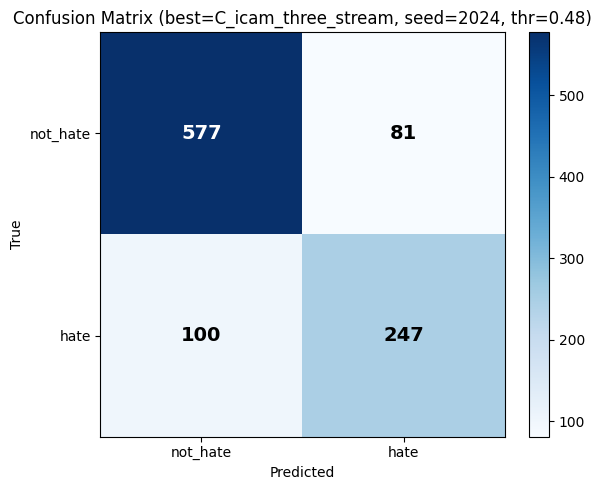


Classification report:
              precision    recall  f1-score   support

    not_hate     0.8523    0.8769    0.8644       658
        hate     0.7530    0.7118    0.7319       347

    accuracy                         0.8199      1005
   macro avg     0.8027    0.7944    0.7981      1005
weighted avg     0.8180    0.8199    0.8186      1005



In [32]:
ckpt_best = DIRS["ablation"] / f"{best_variant}_seed{best_seed}.pt"
model_best = build_variant(best_variant, CONFIG).to(DEVICE)
model_best.load_state_dict(torch.load(ckpt_best, map_location=DEVICE)["state_dict"])
for p in model_best.parameters(): p.requires_grad = False
model_best.eval()

with open(DIRS["ablation"] / f"{best_variant}_seed{best_seed}_result.json") as f:
    best_res = json.load(f)
thr_best = best_res["best_threshold"]

_, dl_val, dl_test = build_loaders(best_seed, with_topic=(best_variant != "D_no_topic"))
test_metrics, prob_hate_test, y_test = evaluate(model_best, dl_test, threshold=thr_best)
y_pred = (prob_hate_test >= thr_best).astype(int)
cm_arr = confusion_matrix(y_test, y_pred)

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(cm_arr, cmap="Blues")
ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
ax.set_xticklabels(["not_hate", "hate"]); ax.set_yticklabels(["not_hate", "hate"])
ax.set_xlabel("Predicted"); ax.set_ylabel("True")
ax.set_title(f"Confusion Matrix (best={best_variant}, seed={best_seed}, thr={thr_best:.2f})")
for i in range(2):
    for j in range(2):
        ax.text(j, i, str(cm_arr[i, j]), ha="center", va="center",
                color="white" if cm_arr[i, j] > cm_arr.max()/2 else "black",
                fontsize=14, fontweight="bold")
plt.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout()
plt.savefig(DIRS["figures"] / "fig04_confusion_matrix.png", dpi=120, bbox_inches="tight")
plt.show()

print("\nClassification report:")
print(classification_report(y_test, y_pred, target_names=["not_hate","hate"], digits=4))

# FREEZE BEST MODEL → XAI SETUP 

## Freeze + Verify

In [33]:
# Freeze model best (sudah dilakukan di Cell 5.7) - re-load dengan eager attn untuk Rollout
model_xai = build_variant(best_variant, CONFIG)
# Re-init image_encoder dengan attn_implementation=eager untuk support output_attentions
model_xai.backbone.image_encoder = ViTModel.from_pretrained(CONFIG["image_model_name"], attn_implementation="eager")
_freeze_bottom(model_xai.backbone.image_encoder.encoder.layer, CONFIG["freeze_n_layers"])
for p in model_xai.backbone.image_encoder.embeddings.parameters(): p.requires_grad = False
model_xai = model_xai.to(DEVICE)
state = torch.load(ckpt_best, map_location=DEVICE)["state_dict"]
missing, unexpected = model_xai.load_state_dict(state, strict=False)
print(f"Loaded best ckpt. Missing={len(missing)}, Unexpected={len(unexpected)}")
for p in model_xai.parameters(): p.requires_grad = False
model_xai.eval()

# Verify accuracy match
ds_test_xai = IndoMemeDataset(df_test, tokenizer, EVAL_TF, CONFIG["max_seq_len"], with_topic=(best_variant != "D_no_topic"))
dl_test_xai = DataLoader(ds_test_xai, batch_size=CONFIG["batch_size"], shuffle=False, num_workers=2, pin_memory=True)
verif_metrics, _, _ = evaluate(model_xai, dl_test_xai, threshold=thr_best)
print(f"Verify: test F1={verif_metrics['macro_f1']:.4f}  (orig: {test_metrics['macro_f1']:.4f})")
assert abs(verif_metrics["macro_f1"] - test_metrics["macro_f1"]) < 0.005, "Mismatch!"

# Activate save_attn untuk model B (dipakai utk Cross-Attn extraction)
if hasattr(model_xai, "save_attn"):
    model_xai.save_attn = True
print(f"Frozen model ready for XAI extraction.")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: indolem/indobertweet-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

Loaded best ckpt. Missing=0, Unexpected=0
Verify: test F1=0.7981  (orig: 0.7981)
Frozen model ready for XAI extraction.


# XAI ATTRIBUTION (4 metode)

## IG (Captum) on Test Set

In [34]:
class _ModelForCaptum(nn.Module):
    def __init__(self, base): super().__init__(); self.base = base
    def forward(self, input_ids, attention_mask, pixel_values, topic):
        return self.base(input_ids, attention_mask, pixel_values, topic)["logits"]

ig_model = _ModelForCaptum(model_xai).to(DEVICE).eval()
text_embed_layer = model_xai.backbone.text_encoder.embeddings
lig = LayerIntegratedGradients(ig_model, text_embed_layer)

dl_test_ig = DataLoader(ds_test_xai, batch_size=4, shuffle=False, num_workers=2, pin_memory=True)
all_token_l2, all_token_sum, all_attn_mask, all_idxs = [], [], [], []
all_pred, all_prob, all_label, all_delta = [], [], [], []
all_tokens = []
print("Running IG on test set...")
t0 = time.time()
for batch in tqdm(dl_test_ig, desc="IG"):
    ids   = batch["input_ids"].to(DEVICE)
    mask  = batch["attention_mask"].to(DEVICE)
    pix   = batch["pixel_values"].to(DEVICE)
    topic = batch["topic"].to(DEVICE)
    baseline = torch.full_like(ids, tokenizer.pad_token_id)
    with torch.no_grad():
        logits = ig_model(ids, mask, pix, topic)
        probs = F.softmax(logits, dim=-1)
        preds = probs.argmax(dim=-1)
    atts, delta = lig.attribute(
        inputs=ids, baselines=baseline,
        additional_forward_args=(mask, pix, topic),
        target=preds, n_steps=CONFIG["ig_n_steps"],
        internal_batch_size=CONFIG["ig_internal_bs"],
        return_convergence_delta=True,
    )
    all_token_l2.append(atts.norm(dim=-1).cpu().numpy())
    all_token_sum.append(atts.sum(dim=-1).cpu().numpy())
    all_attn_mask.append(mask.cpu().numpy().astype(np.int8))
    all_idxs.extend(batch["idx"].tolist())
    all_pred.extend(preds.cpu().tolist())
    all_prob.extend(probs.gather(1, preds.unsqueeze(1)).squeeze(1).cpu().tolist())
    all_label.extend(batch["label"].tolist())
    all_delta.extend(delta.cpu().tolist())
    for i in range(ids.size(0)):
        all_tokens.append(tokenizer.convert_ids_to_tokens(ids[i].cpu().tolist()))

ig_data = dict(
    token_l2=np.concatenate(all_token_l2, axis=0).astype(np.float32),
    token_sum=np.concatenate(all_token_sum, axis=0).astype(np.float32),
    attention_mask=np.concatenate(all_attn_mask, axis=0),
    idxs=np.array(all_idxs, dtype=np.int64),
    pred_class=np.array(all_pred, dtype=np.int8),
    pred_prob=np.array(all_prob, dtype=np.float32),
    true_label=np.array(all_label, dtype=np.int8),
    delta=np.array(all_delta, dtype=np.float32),
)
np.savez_compressed(DIRS["xai"] / "ig_test.npz", **ig_data)
with open(DIRS["xai"] / "ig_tokens.json", "w") as f:
    json.dump([{"idx": int(i), "tokens": t} for i, t in zip(ig_data["idxs"], all_tokens)], f, ensure_ascii=False)
print(f"IG done. {len(all_idxs)} samples, delta_mean={np.abs(ig_data['delta']).mean():.4f}, elapsed={(time.time()-t0)/60:.1f}min")

Running IG on test set...


IG:   0%|          | 0/252 [00:00<?, ?it/s]

IG done. 1005 samples, delta_mean=0.3879, elapsed=27.8min


## Cross-Attention Map (dari Varian B) + Rollout + Incongruity (POST-HOC)

In [35]:
def attention_rollout(attentions, head_fusion="mean"):
    """ViT Rollout: R_l = (A_l + I) · R_{l-1}. Return CLS row (drop CLS token)."""
    result = None
    device = attentions[0].device
    B, H, T, _ = attentions[0].shape
    eye = torch.eye(T, device=device).unsqueeze(0).expand(B, -1, -1)
    for attn in attentions:
        fused = attn.mean(dim=1) if head_fusion == "mean" else attn.max(dim=1).values
        rolled = fused + eye
        rolled = rolled / rolled.sum(dim=-1, keepdim=True).clamp(min=1e-12)
        result = rolled if result is None else torch.bmm(rolled, result)
    return result[:, 0, 1:]                                      # [B, P-1]


@torch.no_grad()
def extract_image_xai_batch(model, batch):
    ids   = batch["input_ids"].to(DEVICE)
    mask  = batch["attention_mask"].to(DEVICE)
    pix   = batch["pixel_values"].to(DEVICE)
    topic = batch["topic"].to(DEVICE)
    G = CONFIG["grid_size"]

    if hasattr(model, "save_attn"): model.save_attn = True
    th, ih, attns = model.backbone.encode(ids, mask, pix, output_attentions=True)
    out = model(ids, mask, pix, topic)
    logits = out["logits"]

    # FIX: cek MULTIPLE attribute name (Var B = last_attn, Var C = last_t2i_attn)
    cross_attn_w = getattr(model, "last_attn", None)
    if cross_attn_w is None:
        cross_attn_w = getattr(model, "last_t2i_attn", None)
    if cross_attn_w is not None:
        ca = cross_attn_w.float()
        mf = mask.float().unsqueeze(-1)
        ca_avg = (ca * mf).sum(dim=1) / mf.sum(dim=1).clamp(min=1.0)
        cross_map = ca_avg[:, 1:].reshape(-1, G, G).cpu().numpy()
    else:
        cross_map = np.zeros((ids.size(0), G, G), dtype=np.float32)

    cls_rel = attention_rollout(attns)
    rollout_map = cls_rel.reshape(-1, G, G).cpu().numpy()

    tn, ino = F.normalize(th, dim=-1), F.normalize(ih, dim=-1)
    sim = torch.bmm(tn, ino.transpose(1, 2))
    incongruity = 1.0 - sim.abs()
    inc_w = F.softmax(incongruity, dim=-1)
    mf = mask.float().unsqueeze(-1)
    inc_avg = (inc_w * mf).sum(dim=1) / mf.sum(dim=1).clamp(min=1.0)
    inc_map = inc_avg[:, 1:].reshape(-1, G, G).cpu().numpy()

    probs = F.softmax(logits.float(), dim=-1)
    preds = probs.argmax(dim=-1)
    pred_probs = probs.gather(1, preds.unsqueeze(1)).squeeze(1)
    return cross_map, rollout_map, inc_map, preds.cpu().numpy(), pred_probs.cpu().numpy()


# Run on test set
all_cross, all_rollout, all_inc, all_preds_x, all_probs_x = [], [], [], [], []
all_idxs_x, all_labels_x, all_paths_x = [], [], []
for batch in tqdm(dl_test_xai, desc="image XAI"):
    cm, rm, im, pr, pp = extract_image_xai_batch(model_xai, batch)
    all_cross.append(cm); all_rollout.append(rm); all_inc.append(im)
    all_preds_x.append(pr); all_probs_x.append(pp)
    all_idxs_x.extend(batch["idx"].tolist())
    all_labels_x.extend(batch["label"].tolist())

all_cross   = np.concatenate(all_cross,   axis=0).astype(np.float32)
all_rollout = np.concatenate(all_rollout, axis=0).astype(np.float32)
all_inc     = np.concatenate(all_inc,     axis=0).astype(np.float32)
all_preds_x = np.concatenate(all_preds_x, axis=0).astype(np.int8)
all_probs_x = np.concatenate(all_probs_x, axis=0).astype(np.float32)
all_idxs_x  = np.array(all_idxs_x, dtype=np.int64)
all_labels_x= np.array(all_labels_x, dtype=np.int8)

np.savez_compressed(DIRS["xai"] / "image_xai.npz",
                     cross_attn=all_cross, rollout=all_rollout, incongruity=all_inc,
                     pred_class=all_preds_x, pred_prob=all_probs_x,
                     true_label=all_labels_x, idxs=all_idxs_x)

# Resolve paths utk visualisasi nanti
def _path_for(idx):
    return df_test[df_test["idx"] == int(idx)]["full_image_path"].values[0]
all_paths_x = [_path_for(i) for i in all_idxs_x]
print(f"Image XAI done. cross_attn shape={all_cross.shape}")

image XAI:   0%|          | 0/32 [00:00<?, ?it/s]

Image XAI done. cross_attn shape=(1005, 14, 14)


## Selectivity Comparison Table

In [36]:
def selectivity_stats(maps, name):
    flat = maps.reshape(len(maps), -1)
    flat_sorted = -np.sort(-flat, axis=1)
    top10 = flat_sorted[:, :10].sum(axis=1) / flat.sum(axis=1).clamp(min=1e-12) if hasattr(flat, "clamp") else flat_sorted[:, :10].sum(axis=1) / np.maximum(flat.sum(axis=1), 1e-12)
    return dict(method=name, mean=float(maps.mean()), std=float(maps.std()),
                max_per_mean=float(maps.max()/maps.mean()),
                top10_share=float(top10.mean()))

xai_stats = pd.DataFrame([
    selectivity_stats(all_cross,   "Cross-Attention (Varian B)"),
    selectivity_stats(all_rollout, "Attention Rollout"),
    selectivity_stats(all_inc,     "Incongruity Heatmap (post-hoc)"),
])
xai_stats.to_csv(DIRS["results"] / "xai_selectivity.csv", index=False)
print(xai_stats.to_string(index=False, float_format=lambda x: f"{x:.5f}" if isinstance(x, float) else str(x)))
print(f"\nIG (text) - convergence delta mean: {np.abs(ig_data['delta']).mean():.4f}")

                        method    mean     std  max_per_mean  top10_share
    Cross-Attention (Varian B) 0.00508 0.00006       1.06278      0.05218
             Attention Rollout 0.00421 0.00108       4.87112      0.08237
Incongruity Heatmap (post-hoc) 0.00508 0.00003       1.04933      0.05155

IG (text) - convergence delta mean: 0.3879


# FAITHFULNESS (PERTURBATION + ROAR) 

## Perturbation Test

In [37]:
def mask_text_top(input_ids, attention_mask, token_l2_arr, idxs_arr, sample_idxs, ratio):
    new_mask = attention_mask.clone()
    SPECIAL = {tokenizer.cls_token_id, tokenizer.sep_token_id, tokenizer.pad_token_id, tokenizer.unk_token_id}
    for b, sidx in enumerate(sample_idxs):
        pos = int(np.where(idxs_arr == int(sidx))[0][0])
        scores = token_l2_arr[pos].copy()
        is_special = np.array([int(t) in SPECIAL for t in input_ids[b].cpu().numpy()])
        is_real    = attention_mask[b].cpu().numpy() == 1
        eligible   = is_real & ~is_special
        scores[~eligible] = -np.inf
        n_elig = int(eligible.sum()); n_mask = max(1, int(round(n_elig * ratio)))
        if n_mask >= n_elig: continue
        top = np.argpartition(-scores, n_mask)[:n_mask]
        new_mask[b, top] = 0
    return input_ids, new_mask

def mask_image_top(pixel_values, maps_arr, idxs_arr, sample_idxs, ratio):
    new_pv = pixel_values.clone()
    G, P = CONFIG["grid_size"], CONFIG["patch_size"]
    n_total = G * G; n_mask = max(1, int(round(n_total * ratio)))
    for b, sidx in enumerate(sample_idxs):
        pos = int(np.where(idxs_arr == int(sidx))[0][0])
        flat = maps_arr[pos].flatten()
        top = np.argpartition(-flat, n_mask)[:n_mask]
        for k in top:
            r, c = int(k) // G, int(k) % G
            new_pv[b, :, r*P:(r+1)*P, c*P:(c+1)*P] = 0.0
    return new_pv

def mask_text_random(input_ids, attention_mask, ratio, rng_seed):
    new_mask = attention_mask.clone()
    SPECIAL = {tokenizer.cls_token_id, tokenizer.sep_token_id, tokenizer.pad_token_id, tokenizer.unk_token_id}
    rng = np.random.RandomState(rng_seed)
    for b in range(input_ids.size(0)):
        is_special = np.array([int(t) in SPECIAL for t in input_ids[b].cpu().numpy()])
        is_real    = attention_mask[b].cpu().numpy() == 1
        elig = np.where(is_real & ~is_special)[0]
        n_mask = max(1, int(round(len(elig) * ratio)))
        if n_mask >= len(elig): continue
        new_mask[b, rng.choice(elig, n_mask, replace=False)] = 0
    return input_ids, new_mask

def mask_image_random(pixel_values, ratio, rng_seed):
    new_pv = pixel_values.clone()
    G, P = CONFIG["grid_size"], CONFIG["patch_size"]
    n_total = G * G; n_mask = max(1, int(round(n_total * ratio)))
    rng = np.random.RandomState(rng_seed)
    for b in range(pixel_values.size(0)):
        top = rng.choice(n_total, n_mask, replace=False)
        for k in top:
            r, c = int(k) // G, int(k) % G
            new_pv[b, :, r*P:(r+1)*P, c*P:(c+1)*P] = 0.0
    return new_pv


@torch.no_grad()
def eval_pertub(model, loader, mask_target=None, mask_ratio=0.0,
                 attr_arr=None, idxs_arr=None, rng_seed=42):
    model.eval()
    all_logits, all_labels = [], []
    for bi, batch in enumerate(tqdm(loader, leave=False)):
        ids   = batch["input_ids"].to(DEVICE)
        mask  = batch["attention_mask"].to(DEVICE)
        pix   = batch["pixel_values"].to(DEVICE)
        topic = batch["topic"].to(DEVICE)
        sidx  = batch["idx"].cpu().numpy() if torch.is_tensor(batch["idx"]) else np.array(batch["idx"])
        if mask_target == "ig_text":
            ids, mask = mask_text_top(ids, mask, attr_arr, idxs_arr, sidx, mask_ratio)
        elif mask_target == "random_text":
            ids, mask = mask_text_random(ids, mask, mask_ratio, rng_seed + bi)
        elif mask_target in ("cross_attn", "rollout", "incongruity"):
            pix = mask_image_top(pix, attr_arr, idxs_arr, sidx, mask_ratio)
        elif mask_target == "random_image":
            pix = mask_image_random(pix, mask_ratio, rng_seed + bi)
        with autocast(device_type="cuda"):
            out = model(ids, mask, pix, topic)
        all_logits.append(out["logits"].float().cpu()); all_labels.append(batch["label"])
    logits = torch.cat(all_logits); labels = torch.cat(all_labels).numpy()
    probs  = F.softmax(logits, dim=-1).numpy()
    preds  = probs.argmax(axis=-1)
    return dict(macro_f1=float(f1_score(labels, preds, average="macro")),
                hate_r=float(recall_score(labels, preds, pos_label=1, zero_division=0)),
                hate_f1=float(f1_score(labels, preds, pos_label=1, zero_division=0)),
                accuracy=float(accuracy_score(labels, preds)))


# Run all perturbations
print("Baseline (no mask)...")
baseline_pert = eval_pertub(model_xai, dl_test_xai)
print(f"  baseline F1={baseline_pert['macro_f1']:.4f}")

pertub_results = {"baseline": baseline_pert}
for ratio in CONFIG["mask_levels"]:
    pct = int(ratio*100)
    pertub_results[f"ig_{pct}"]          = eval_pertub(model_xai, dl_test_xai, "ig_text",     ratio, ig_data["token_l2"], ig_data["idxs"])
    pertub_results[f"random_text_{pct}"] = eval_pertub(model_xai, dl_test_xai, "random_text", ratio)
    pertub_results[f"cross_attn_{pct}"]  = eval_pertub(model_xai, dl_test_xai, "cross_attn",  ratio, all_cross,   all_idxs_x)
    pertub_results[f"rollout_{pct}"]     = eval_pertub(model_xai, dl_test_xai, "rollout",     ratio, all_rollout, all_idxs_x)
    pertub_results[f"incongruity_{pct}"] = eval_pertub(model_xai, dl_test_xai, "incongruity", ratio, all_inc,     all_idxs_x)
    pertub_results[f"random_image_{pct}"]= eval_pertub(model_xai, dl_test_xai, "random_image",ratio)
    print(f"  ratio={pct}% done.")

with open(DIRS["roar"] / "perturbation_results.json", "w") as f:
    json.dump(pertub_results, f, indent=2)

# Print verdict
print("\n=== PERTURBATION VERDICT ===")
print(f"Baseline F1: {baseline_pert['macro_f1']:.4f}")
for pct in [10, 20, 30]:
    d_ig    = pertub_results[f"ig_{pct}"]["macro_f1"]          - baseline_pert["macro_f1"]
    d_rtxt  = pertub_results[f"random_text_{pct}"]["macro_f1"] - baseline_pert["macro_f1"]
    print(f"  IG @ {pct}%   d={d_ig:+.4f} | random_text d={d_rtxt:+.4f} | diff={d_ig-d_rtxt:+.4f} -> {'FAITHFUL' if d_ig-d_rtxt < -0.005 else 'WEAK'}")
    for m in ["cross_attn", "rollout", "incongruity"]:
        d_m   = pertub_results[f"{m}_{pct}"]["macro_f1"]       - baseline_pert["macro_f1"]
        d_rim = pertub_results[f"random_image_{pct}"]["macro_f1"] - baseline_pert["macro_f1"]
        print(f"  {m:12s} d={d_m:+.4f} | random_image d={d_rim:+.4f} | diff={d_m-d_rim:+.4f}")

Baseline (no mask)...


  0%|          | 0/32 [00:00<?, ?it/s]

  baseline F1=0.7979


  0%|          | 0/32 [00:00<?, ?it/s]

  0%|          | 0/32 [00:00<?, ?it/s]

  0%|          | 0/32 [00:00<?, ?it/s]

... (16 outputs left out)

  0%|          | 0/32 [00:00<?, ?it/s]

  0%|          | 0/32 [00:00<?, ?it/s]

  0%|          | 0/32 [00:00<?, ?it/s]

  ratio=30% done.

=== PERTURBATION VERDICT ===
Baseline F1: 0.7979
  IG @ 10%   d=-0.0498 | random_text d=-0.0106 | diff=-0.0392 -> FAITHFUL
  cross_attn   d=+0.0048 | random_image d=+0.0016 | diff=+0.0032
  rollout      d=-0.0035 | random_image d=+0.0016 | diff=-0.0052
  incongruity  d=-0.0022 | random_image d=+0.0016 | diff=-0.0039
  IG @ 20%   d=-0.0794 | random_text d=-0.0176 | diff=-0.0618 -> FAITHFUL
  cross_attn   d=-0.0032 | random_image d=-0.0029 | diff=-0.0003
  rollout      d=+0.0009 | random_image d=-0.0029 | diff=+0.0038
  incongruity  d=-0.0019 | random_image d=-0.0029 | diff=+0.0010
  IG @ 30%   d=-0.0751 | random_text d=-0.0297 | diff=-0.0454 -> FAITHFUL
  cross_attn   d=-0.0022 | random_image d=+0.0010 | diff=-0.0032
  rollout      d=-0.0051 | random_image d=+0.0010 | diff=-0.0061
  incongruity  d=+0.0004 | random_image d=+0.0010 | diff=-0.0006


## ROAR Retrain (Compact, resume-friendly)

In [38]:
# ROAR subset 2000 train (stratified)
rng = np.random.RandomState(CONFIG["seed"])
n_target = CONFIG["roar_train_size"]
hate_idx = df_train[df_train["label"] == 1].index.values
not_idx  = df_train[df_train["label"] == 0].index.values
n_h = int(n_target * (len(hate_idx) / len(df_train)))
sel = np.concatenate([rng.choice(hate_idx, n_h, replace=False),
                       rng.choice(not_idx, n_target - n_h, replace=False)])
rng.shuffle(sel)
df_train_roar = df_train.iloc[sel].reset_index(drop=True)
print(f"ROAR train subset: {len(df_train_roar)}")

# We need attribution for training subset too. Compute IG + image methods.
print("\nComputing training attributions for ROAR (slow ~30 min)...")
ds_train_attr = IndoMemeDataset(df_train_roar, tokenizer, EVAL_TF, CONFIG["max_seq_len"], with_topic=(best_variant != "D_no_topic"))
dl_train_ig = DataLoader(ds_train_attr, batch_size=4, shuffle=False, num_workers=2, pin_memory=True)
dl_train_im = DataLoader(ds_train_attr, batch_size=CONFIG["batch_size"], shuffle=False, num_workers=2, pin_memory=True)

train_ig_path = DIRS["roar"] / "train_ig.npz"
train_im_path = DIRS["roar"] / "train_image_xai.npz"

if not train_ig_path.exists():
    tl2_list, idx_list = [], []
    for batch in tqdm(dl_train_ig, desc="train IG"):
        ids = batch["input_ids"].to(DEVICE); mask = batch["attention_mask"].to(DEVICE)
        pix = batch["pixel_values"].to(DEVICE); topic = batch["topic"].to(DEVICE)
        baseline = torch.full_like(ids, tokenizer.pad_token_id)
        with torch.no_grad():
            preds = ig_model(ids, mask, pix, topic).argmax(dim=-1)
        atts = lig.attribute(inputs=ids, baselines=baseline,
                              additional_forward_args=(mask, pix, topic),
                              target=preds, n_steps=CONFIG["ig_n_steps"],
                              internal_batch_size=CONFIG["ig_internal_bs"])
        tl2_list.append(atts.norm(dim=-1).cpu().numpy())
        idx_list.extend(batch["idx"].tolist())
    np.savez_compressed(train_ig_path, token_l2=np.concatenate(tl2_list).astype(np.float32),
                         idxs=np.array(idx_list, dtype=np.int64))
    print(f"  saved {train_ig_path}")

if not train_im_path.exists():
    tc, tr, ti, tidx = [], [], [], []
    for batch in tqdm(dl_train_im, desc="train image XAI"):
        cm, rm, im, _, _ = extract_image_xai_batch(model_xai, batch)
        tc.append(cm); tr.append(rm); ti.append(im)
        tidx.extend(batch["idx"].tolist())
    np.savez_compressed(train_im_path,
                         cross_attn=np.concatenate(tc).astype(np.float32),
                         rollout=np.concatenate(tr).astype(np.float32),
                         incongruity=np.concatenate(ti).astype(np.float32),
                         idxs=np.array(tidx, dtype=np.int64))
    print(f"  saved {train_im_path}")

print("Train attributions ready.")

ROAR train subset: 2000

Computing training attributions for ROAR (slow ~30 min)...
Train attributions ready.


##  ROAR Retrain Loop

In [39]:
# ROAR Dataset class (with masking)
class ROARDataset(Dataset):
    def __init__(self, df_split, tokenizer, transform, max_seq_len, with_topic,
                 mask_method, mask_level, attr_arr, idxs_arr, mask_domain="text", rng_seed=0):
        self.df = df_split.reset_index(drop=True)
        self.tokenizer = tokenizer; self.transform = transform; self.max_seq_len = max_seq_len
        self.with_topic = with_topic
        self.mask_method = mask_method; self.mask_level = mask_level
        self.mask_domain = mask_domain
        self.attr_arr = attr_arr; self.idxs_arr = idxs_arr
        self.rng_seed = rng_seed
        self.SPECIAL = {tokenizer.cls_token_id, tokenizer.sep_token_id, tokenizer.pad_token_id, tokenizer.unk_token_id}

    def __len__(self): return len(self.df)

    def _idx_to_pos(self, sidx):
        if self.idxs_arr is None: return None
        m = np.where(self.idxs_arr == int(sidx))[0]
        return int(m[0]) if len(m) else None

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img = Image.open(row["full_image_path"]).convert("RGB")
        img_t = self.transform(img)
        text_col = "text_input" if self.with_topic else "text_input_no_topic"
        enc = self.tokenizer(row[text_col], padding="max_length", truncation=True,
                              max_length=self.max_seq_len, return_tensors="pt")
        ids = enc["input_ids"].squeeze(0); mask = enc["attention_mask"].squeeze(0)
        sidx = int(row["idx"])

        if self.mask_method and self.mask_level > 0:
            if self.mask_domain == "text":
                if self.mask_method == "ig_text":
                    pos = self._idx_to_pos(sidx)
                    if pos is not None:
                        scores = self.attr_arr[pos].copy()
                        is_special = np.array([int(t) in self.SPECIAL for t in ids.numpy()])
                        is_real    = mask.numpy() == 1
                        elig = is_real & ~is_special
                        scores[~elig] = -np.inf
                        n_elig = int(elig.sum()); n_m = max(1, int(round(n_elig * self.mask_level)))
                        if n_m < n_elig:
                            mask[np.argpartition(-scores, n_m)[:n_m]] = 0
                elif self.mask_method == "random":
                    rng = np.random.RandomState(self.rng_seed + sidx)
                    is_special = np.array([int(t) in self.SPECIAL for t in ids.numpy()])
                    is_real = mask.numpy() == 1
                    elig = np.where(is_real & ~is_special)[0]
                    n_m = max(1, int(round(len(elig) * self.mask_level)))
                    if n_m < len(elig): mask[rng.choice(elig, n_m, replace=False)] = 0
            elif self.mask_domain == "image":
                G, P = CONFIG["grid_size"], CONFIG["patch_size"]
                n_total = G*G; n_m = max(1, int(round(n_total * self.mask_level)))
                if self.mask_method == "random":
                    rng = np.random.RandomState(self.rng_seed + sidx)
                    top = rng.choice(n_total, n_m, replace=False)
                else:
                    pos = self._idx_to_pos(sidx)
                    if pos is None: top = []
                    else:
                        flat = self.attr_arr[pos].flatten()
                        top = np.argpartition(-flat, n_m)[:n_m]
                for k in top:
                    r, c = int(k)//G, int(k)%G
                    img_t[:, r*P:(r+1)*P, c*P:(c+1)*P] = 0.0

        return {"input_ids": ids, "attention_mask": mask, "pixel_values": img_t,
                "topic": torch.from_numpy(row["topic_multihot"]),
                "label": torch.tensor(int(row["label"]), dtype=torch.long),
                "idx": sidx}


# Build ROAR retrain configs
ROAR_CONFIGS = [{"name": "roar_baseline", "method": None, "level": 0.0, "domain": None, "attr_path": None}]
ig_train_data = np.load(train_ig_path)
im_train_data = np.load(train_im_path)
test_attr_paths = {
    "ig_text":     (ig_data["token_l2"], ig_data["idxs"]),
    "cross_attn":  (all_cross,   all_idxs_x),
    "rollout":     (all_rollout, all_idxs_x),
    "incongruity": (all_inc,     all_idxs_x),
}
train_attr_paths = {
    "ig_text":     (ig_train_data["token_l2"],   ig_train_data["idxs"]),
    "cross_attn":  (im_train_data["cross_attn"], im_train_data["idxs"]),
    "rollout":     (im_train_data["rollout"],    im_train_data["idxs"]),
    "incongruity": (im_train_data["incongruity"],im_train_data["idxs"]),
}
for lv in CONFIG["mask_levels"]:
    pct = int(lv*100)
    ROAR_CONFIGS.append({"name": f"ig_{pct}", "method": "ig_text", "level": lv, "domain": "text"})
    ROAR_CONFIGS.append({"name": f"random_text_{pct}", "method": "random", "level": lv, "domain": "text"})
    for m in ["cross_attn", "rollout", "incongruity"]:
        ROAR_CONFIGS.append({"name": f"{m}_{pct}", "method": m, "level": lv, "domain": "image"})
    ROAR_CONFIGS.append({"name": f"random_image_{pct}", "method": "random", "level": lv, "domain": "image"})

# ROAR retrain loop
roar_results = {}
labels_train_roar = df_train_roar["label"].values
cc = np.bincount(labels_train_roar, minlength=2)
sw_roar = 1.0 / cc[labels_train_roar]

for r_cfg in ROAR_CONFIGS:
    name = r_cfg["name"]
    res_path = DIRS["roar"] / f"{name}.json"
    if res_path.exists():
        with open(res_path) as f: roar_results[name] = json.load(f)
        print(f"[skip] {name}"); continue
    print(f"\n=== ROAR: {name} ===")
    set_seed(CONFIG["seed"])
    method = r_cfg["method"]; level = r_cfg["level"]; domain = r_cfg["domain"]
    train_attr = train_attr_paths.get(method, (None, None)) if method and method != "random" else (None, None)
    test_attr  = test_attr_paths.get(method, (None, None))  if method and method != "random" else (None, None)

    ds_tr = ROARDataset(df_train_roar, tokenizer, TRAIN_TF, CONFIG["max_seq_len"],
                         with_topic=(best_variant != "D_no_topic"),
                         mask_method=method, mask_level=level,
                         attr_arr=train_attr[0], idxs_arr=train_attr[1], mask_domain=domain or "text")
    ds_te = ROARDataset(df_test, tokenizer, EVAL_TF, CONFIG["max_seq_len"],
                         with_topic=(best_variant != "D_no_topic"),
                         mask_method=method, mask_level=level,
                         attr_arr=test_attr[0], idxs_arr=test_attr[1], mask_domain=domain or "text")
    g = torch.Generator(); g.manual_seed(CONFIG["seed"])
    sampler = WeightedRandomSampler(weights=torch.from_numpy(sw_roar).double(),
                                     num_samples=len(sw_roar), replacement=True, generator=g)
    dl_tr = DataLoader(ds_tr, batch_size=CONFIG["batch_size"], sampler=sampler, num_workers=2, pin_memory=True)
    dl_te = DataLoader(ds_te, batch_size=CONFIG["batch_size"], shuffle=False, num_workers=2, pin_memory=True)

    m_roar = build_variant(best_variant, CONFIG).to(DEVICE)
    n_steps = math.ceil(len(dl_tr) / CONFIG["grad_accum"]) * CONFIG["roar_num_epochs"]
    opt, sch = build_optim_sched(m_roar, CONFIG, n_steps)
    scaler = GradScaler("cuda")
    focal_fn = FocalLoss(gamma=CONFIG["focal_gamma"], alpha=CONFIG["class_weights"], label_smoothing=CONFIG["label_smoothing"])
    supcon_fn = SupConLoss(temperature=CONFIG["supcon_temperature"])
    best_test_f1 = -1.0; best_metrics = None
    for ep in range(1, CONFIG["roar_num_epochs"] + 1):
        train_one_epoch(m_roar, dl_tr, opt, sch, focal_fn, supcon_fn, scaler, CONFIG, ep)
        test_metrics, _, _ = evaluate(m_roar, dl_te, threshold=0.5)
        if test_metrics["macro_f1"] > best_test_f1:
            best_test_f1 = test_metrics["macro_f1"]; best_metrics = test_metrics
    roar_results[name] = {"name": name, "test_metrics": best_metrics, **r_cfg}
    with open(res_path, "w") as f: json.dump(roar_results[name], f, indent=2, default=str)
    print(f"  done {name}: F1={best_test_f1:.4f}")
    del m_roar, opt, sch, scaler; torch.cuda.empty_cache(); gc.collect()
print(f"\n{'='*60}\nROAR DONE: {len(roar_results)} runs\n{'='*60}")

[skip] roar_baseline
[skip] ig_10
[skip] random_text_10
[skip] cross_attn_10
[skip] rollout_10
[skip] incongruity_10
[skip] random_image_10
[skip] ig_20
[skip] random_text_20
[skip] cross_attn_20
[skip] rollout_20
[skip] incongruity_20
[skip] random_image_20
[skip] ig_30
[skip] random_text_30
[skip] cross_attn_30
[skip] rollout_30
[skip] incongruity_30
[skip] random_image_30

ROAR DONE: 19 runs


## ROAR Aggregate + Verdict

ROAR baseline F1 = 0.7840
           name      method domain  level  test_f1  delta_f1
          ig_10     ig_text   text 0.1000   0.7458   -0.0383
 random_text_10      random   text 0.1000   0.7746   -0.0094
  cross_attn_10  cross_attn  image 0.1000   0.7845    0.0005
     rollout_10     rollout  image 0.1000   0.7850    0.0010
 incongruity_10 incongruity  image 0.1000   0.7872    0.0032
random_image_10      random  image 0.1000   0.7860    0.0020
          ig_20     ig_text   text 0.2000   0.7291   -0.0549
 random_text_20      random   text 0.2000   0.7623   -0.0217
  cross_attn_20  cross_attn  image 0.2000   0.7820   -0.0020
     rollout_20     rollout  image 0.2000   0.7812   -0.0028
 incongruity_20 incongruity  image 0.2000   0.7860    0.0020
random_image_20      random  image 0.2000   0.7854    0.0014
          ig_30     ig_text   text 0.3000   0.7335   -0.0505
 random_text_30      random   text 0.3000   0.7473   -0.0368
  cross_attn_30  cross_attn  image 0.3000   0.7812   -0.002

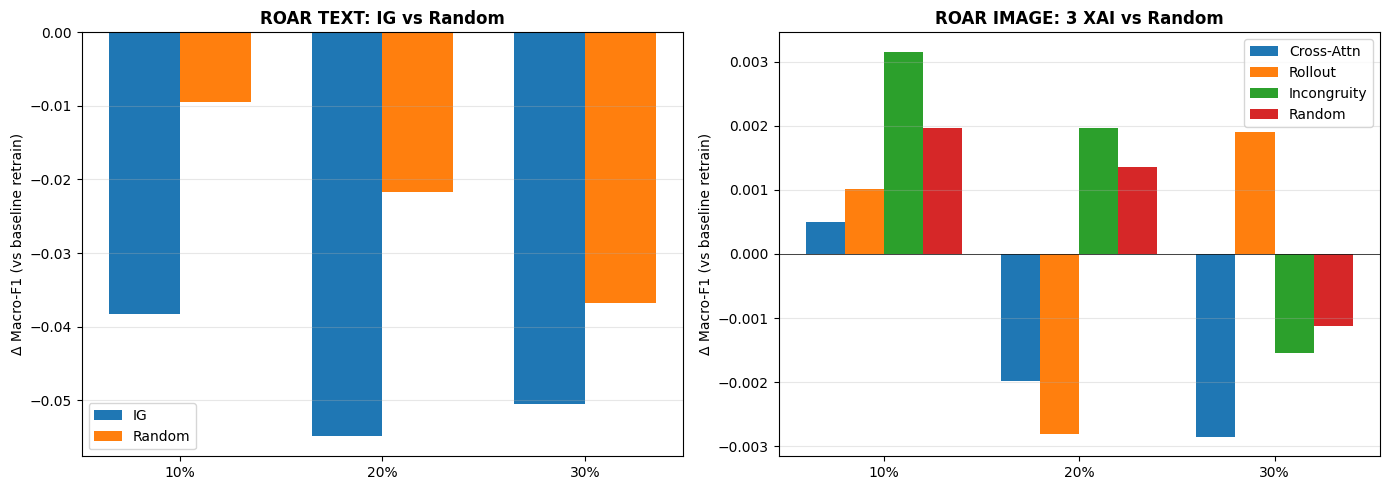

In [40]:
baseline_roar_f1 = roar_results["roar_baseline"]["test_metrics"]["macro_f1"]
roar_rows = []
for c in ROAR_CONFIGS:
    if c["name"] == "roar_baseline": continue
    res = roar_results[c["name"]]
    f1 = res["test_metrics"]["macro_f1"]
    roar_rows.append(dict(name=c["name"], method=c["method"], domain=c["domain"], level=c["level"],
                           test_f1=f1, delta_f1=f1-baseline_roar_f1))
df_roar = pd.DataFrame(roar_rows)
df_roar.to_csv(DIRS["results"] / "roar_results.csv", index=False)
print(f"ROAR baseline F1 = {baseline_roar_f1:.4f}")
print(df_roar.to_string(index=False, float_format=lambda x: f"{x:.4f}" if isinstance(x, float) else str(x)))

# ROAR figure
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
levels = [10, 20, 30]; xpos = np.arange(len(levels))

for ax_i, (title, methods, w) in enumerate([
    ("ROAR TEXT: IG vs Random", [("ig", "IG"), ("random_text", "Random")], 0.35),
    ("ROAR IMAGE: 3 XAI vs Random", [("cross_attn", "Cross-Attn"), ("rollout", "Rollout"),
                                       ("incongruity", "Incongruity"), ("random_image", "Random")], 0.20),
]):
    for i, (m_key, m_label) in enumerate(methods):
        deltas = []
        for lv in levels:
            row = df_roar[(df_roar["name"] == f"{m_key}_{lv}")]
            deltas.append(row["delta_f1"].values[0] if len(row) else 0)
        axes[ax_i].bar(xpos + i*w, deltas, w, label=m_label)
    axes[ax_i].set_xticks(xpos + w*(len(methods)-1)/2); axes[ax_i].set_xticklabels([f"{lv}%" for lv in levels])
    axes[ax_i].set_ylabel("Δ Macro-F1 (vs baseline retrain)"); axes[ax_i].set_title(title, fontweight="bold")
    axes[ax_i].axhline(0, color="black", linewidth=0.5); axes[ax_i].legend(); axes[ax_i].grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(DIRS["figures"] / "fig05_roar.png", dpi=120, bbox_inches="tight")
plt.show()

# VISUALIZATION & CASE STUDIES

In [41]:
"""
RESUME CELL — load semua artifact yang sudah tersimpan ke memory.
Pakai ini kalau kernel restart atau Save Version, supaya tidak perlu re-run Section 5-8.
"""

# 1) Pointer best model dari ablation
with open(DIRS["results"] / "best_model_pointer.json") as f:
    bp = json.load(f)
best_variant = bp["best_variant"]
best_seed    = bp["best_seed"]
ckpt_best    = Path(bp["ckpt_path"])
print(f"Best model: {best_variant}, seed={best_seed}")

# 2) Re-load best result + threshold
with open(DIRS["ablation"] / f"{best_variant}_seed{best_seed}_result.json") as f:
    best_res = json.load(f)
thr_best = best_res["best_threshold"]
test_metrics = best_res["test_metrics"]

# 3) Re-load model_xai (frozen, with eager attention untuk Rollout)
if "model_xai" not in globals():
    model_xai = build_variant(best_variant, CONFIG)
    model_xai.backbone.image_encoder = ViTModel.from_pretrained(
        CONFIG["image_model_name"], attn_implementation="eager")
    _freeze_bottom(model_xai.backbone.image_encoder.encoder.layer, CONFIG["freeze_n_layers"])
    for p in model_xai.backbone.image_encoder.embeddings.parameters(): p.requires_grad = False
    model_xai = model_xai.to(DEVICE)
    state = torch.load(ckpt_best, map_location=DEVICE)["state_dict"]
    model_xai.load_state_dict(state, strict=False)
    for p in model_xai.parameters(): p.requires_grad = False
    model_xai.eval()
    if hasattr(model_xai, "save_attn"): model_xai.save_attn = True
    print("Loaded model_xai from checkpoint.")

# 4) Re-load IG attribution
ig_path = DIRS["xai"] / "ig_test.npz"
if ig_path.exists():
    ig_npz = np.load(ig_path)
    ig_data = {k: ig_npz[k] for k in ig_npz.files}
    print(f"Loaded IG: {ig_data['token_l2'].shape}")
else:
    print("WARNING: ig_test.npz tidak ada, perlu run Section 7.1 dulu")

# 5) Re-load image XAI
img_xai_path = DIRS["xai"] / "image_xai.npz"
if img_xai_path.exists():
    img_npz = np.load(img_xai_path)
    all_cross    = img_npz["cross_attn"]
    all_rollout  = img_npz["rollout"]
    all_inc      = img_npz["incongruity"]
    all_preds_x  = img_npz["pred_class"]
    all_probs_x  = img_npz["pred_prob"]
    all_labels_x = img_npz["true_label"]
    all_idxs_x   = img_npz["idxs"]
    print(f"Loaded image XAI: cross_attn shape={all_cross.shape}")
else:
    print("WARNING: image_xai.npz tidak ada, perlu run Section 7.2 dulu")

# 6) Loaders ulang untuk evaluasi (ringan)
ds_test_xai = IndoMemeDataset(df_test, tokenizer, EVAL_TF, CONFIG["max_seq_len"],
                               with_topic=(best_variant != "D_no_topic"))
dl_test_xai = DataLoader(ds_test_xai, batch_size=CONFIG["batch_size"],
                          shuffle=False, num_workers=2, pin_memory=True)

# 7) IG model wrapper untuk Captum (kalau perlu re-run Section 8)
class _ModelForCaptum(nn.Module):
    def __init__(self, base): super().__init__(); self.base = base
    def forward(self, input_ids, attention_mask, pixel_values, topic):
        return self.base(input_ids, attention_mask, pixel_values, topic)["logits"]

if "ig_model" not in globals():
    ig_model = _ModelForCaptum(model_xai).to(DEVICE).eval()
    text_embed_layer = model_xai.backbone.text_encoder.embeddings
    lig = LayerIntegratedGradients(ig_model, text_embed_layer)

# 8) Re-load ablation results dari per-seed json
ablation_results = {}
for v in CONFIG["ablation_variants"]:
    ablation_results[v] = []
    for s in CONFIG["ablation_seeds"]:
        rp = DIRS["ablation"] / f"{v}_seed{s}_result.json"
        if rp.exists():
            with open(rp) as f: ablation_results[v].append(json.load(f))
print(f"Loaded ablation results.")

# 9) Re-load aggregate ablation table
df_ablation = pd.read_csv(DIRS["results"] / "ablation_results.csv") if (DIRS["results"]/"ablation_results.csv").exists() else None

# 10) Re-load ROAR results kalau sudah ada
roar_results = {}
for rp in DIRS["roar"].glob("*.json"):
    if rp.stem in ("perturbation_results",): continue
    with open(rp) as f: roar_results[rp.stem] = json.load(f)
print(f"Loaded {len(roar_results)} ROAR results from disk.")

# 11) Re-load perturbation kalau ada
pert_path = DIRS["roar"] / "perturbation_results.json"
if pert_path.exists():
    with open(pert_path) as f: pertub_results = json.load(f)
    baseline_pert = pertub_results["baseline"]
    print(f"Loaded perturbation results.")

# 12) Re-load XAI selectivity stats
sel_path = DIRS["results"] / "xai_selectivity.csv"
if sel_path.exists():
    xai_stats = pd.read_csv(sel_path)
    print(f"Loaded xai_selectivity.")

# 13) Re-load best_seed_runs untuk Section 10
if "best_seed_runs" not in globals() and best_variant in ablation_results:
    best_seed_runs = sorted(ablation_results[best_variant], key=lambda r: -r["test_metrics"]["macro_f1"])

# 14) Re-load ensemble kalau ada
ens_path = DIRS["results"] / "ensemble_results.json"
if ens_path.exists():
    with open(ens_path) as f: ens_metrics = json.load(f)
    print(f"Loaded ensemble: F1={ens_metrics['macro_f1']:.4f}")

# 15) Re-load EDA summary
with open(DIRS["results"] / "eda_summary.json") as f: eda_summary = json.load(f)

# 16) Re-load df_roar table kalau ROAR sudah selesai
roar_csv = DIRS["results"] / "roar_results.csv"
if roar_csv.exists():
    df_roar = pd.read_csv(roar_csv)
    baseline_roar_f1 = roar_results.get("roar_baseline", {}).get("test_metrics", {}).get("macro_f1")
    print("Loaded df_roar.")

print("\nRESUME COMPLETE. Sekarang bisa langsung lanjut ke Cell 9.1+ atau Cell 10.")

Best model: C_icam_three_stream, seed=2024
Loaded IG: (1005, 128)
Loaded image XAI: cross_attn shape=(1005, 14, 14)
Loaded ablation results.
Loaded 19 ROAR results from disk.
Loaded perturbation results.
Loaded xai_selectivity.
Loaded df_roar.

RESUME COMPLETE. Sekarang bisa langsung lanjut ke Cell 9.1+ atau Cell 10.


## Helpers + Sample Selection

In [42]:
def overlay_attn(img_pil, attn_14x14, alpha=0.5):
    H = W = CONFIG["img_size"]
    at = torch.from_numpy(attn_14x14).float().unsqueeze(0).unsqueeze(0)
    au = F.interpolate(at, size=(H, W), mode="bilinear", align_corners=False).squeeze().numpy()
    a_min, a_max = au.min(), au.max()
    norm = (au - a_min) / (a_max - a_min + 1e-8)
    cmap = plt.get_cmap("jet")        # FIX: pakai plt.get_cmap, hindari namespace conflict
    heat = cmap(norm)[..., :3]
    img_arr = np.asarray(img_pil.resize((W, H))).astype(np.float32) / 255.0
    if img_arr.ndim == 2: img_arr = np.stack([img_arr]*3, axis=-1)
    if img_arr.shape[-1] == 4: img_arr = img_arr[..., :3]
    return np.clip((1-alpha)*img_arr + alpha*heat, 0, 1)

def render_text_attribution(ax, tokens, scores, mask, max_show=60, title="IG"):
    SPECIAL = {"[CLS]","[SEP]","[PAD]","[UNK]"}
    real = [(t, s) for t, s, m in zip(tokens, scores, mask) if m and t not in SPECIAL][:max_show]
    if not real: ax.set_title(title); ax.axis("off"); return
    rs = np.array([s for _, s in real]); s_min, s_max = rs.min(), rs.max()
    norm = (rs - s_min) / (s_max - s_min + 1e-8)
    cmap = plt.cm.Reds                # tetap pakai plt.cm (lebih aman daripada `import matplotlib.cm as cm`)
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.axis("off")
    n = len(real); cols = 12; rows = math.ceil(n/cols); cell_w = 1.0/cols; cell_h = 0.85/max(rows,1)
    for i, ((tok, sc), nrm) in enumerate(zip(real, norm)):
        r, c = i//cols, i%cols
        x = c*cell_w + cell_w*0.5; y = 0.92 - (r+0.5)*cell_h
        ax.text(x, y, tok, fontsize=8, ha="center", va="center", family="monospace",
                bbox=dict(facecolor=cmap(0.15+0.7*float(nrm)), edgecolor="gray", linewidth=0.3, pad=2, boxstyle="round,pad=0.15"))
    ax.set_title(title, fontsize=10)


# Build df_meta utk seleksi
df_meta = pd.DataFrame({"idx": all_idxs_x, "pred": all_preds_x, "true": all_labels_x, "prob": all_probs_x})
df_meta = df_meta.merge(df_test[["idx","topic","full_image_path"]], on="idx", how="left")
df_meta["category"] = df_meta.apply(
    lambda r: ("TP" if r["pred"]==1 and r["true"]==1 else "TN" if r["pred"]==0 and r["true"]==0
               else "FP" if r["pred"]==1 and r["true"]==0 else "FN"), axis=1)

def select_diverse(df_sub, n, seed=42):
    rng = np.random.RandomState(seed); pool = df_sub["topic"].value_counts().index.tolist()
    chosen, used = [], set()
    for tt in pool:
        if len(chosen) >= n: break
        cand = df_sub[df_sub["topic"] == tt]
        if len(cand) == 0 or tt in used: continue
        chosen.append(cand.sample(1, random_state=int(rng.randint(0, 1e6))).iloc[0]); used.add(tt)
    while len(chosen) < n:
        rem = df_sub[~df_sub["idx"].isin([s["idx"] for s in chosen])]
        if len(rem) == 0: break
        chosen.append(rem.sample(1, random_state=int(rng.randint(0, 1e6))).iloc[0])
    return chosen

selected = []
for cat, n in [("TP", 3), ("TN", 3), ("FP", 2), ("FN", 2)]:
    selected += select_diverse(df_meta[df_meta["category"] == cat], n, seed=hash(cat) % 10000)
print(f"Selected {len(selected)} samples for case study")

Selected 10 samples for case study


## Generate Case Study Figures

In [43]:
# Build idx -> pos map for all attribution arrays
def get_pos(target_idx, idxs_arr):
    return int(np.where(idxs_arr == int(target_idx))[0][0])

with open(DIRS["xai"] / "ig_tokens.json") as f:
    ig_tokens_dict = {item["idx"]: item["tokens"] for item in json.load(f)}

for i, s in enumerate(selected):
    pos_img = get_pos(s["idx"], all_idxs_x)
    pos_ig  = get_pos(s["idx"], ig_data["idxs"])
    img = Image.open(s["full_image_path"]).convert("RGB")
    fig = plt.figure(figsize=(20, 8))
    gs = fig.add_gridspec(2, 4, height_ratios=[3, 1.2], hspace=0.25, wspace=0.10)
    ax = fig.add_subplot(gs[0, 0]); ax.imshow(img.resize((CONFIG["img_size"],CONFIG["img_size"])))
    ax.set_title(f"Original\nidx={s['idx']}  topic={s['topic']}", fontsize=10); ax.axis("off")
    for j, (name, m) in enumerate([("Cross-Attention (Var B)", all_cross[pos_img]),
                                    ("ViT Attention Rollout",   all_rollout[pos_img]),
                                    ("Incongruity (post-hoc)",  all_inc[pos_img])]):
        ax = fig.add_subplot(gs[0, j+1]); ax.imshow(overlay_attn(img, m, alpha=0.5))
        ax.set_title(name, fontsize=10); ax.axis("off")
    ax_t = fig.add_subplot(gs[1, :])
    render_text_attribution(ax_t, ig_tokens_dict[int(s["idx"])],
                              ig_data["token_l2"][pos_ig], ig_data["attention_mask"][pos_ig],
                              title="Integrated Gradients (Text Tokens)")
    pred_str = "hate" if s["pred"]==1 else "not_hate"
    true_str = "hate" if s["true"]==1 else "not_hate"
    fig.suptitle(f"[{s['category']}] pred={pred_str} ({s['prob']:.0%}) | true={true_str} | topic={s['topic']}",
                  fontsize=12, fontweight="bold")
    safe_topic = re.sub(r"[^\w]+", "_", str(s["topic"]))[:30]
    plt.savefig(DIRS["figures"] / f"case_{i+1:02d}_{s['category']}_idx{s['idx']}_{safe_topic}.png", dpi=120, bbox_inches="tight")
    plt.close(fig)
print(f"Generated {len(selected)} case study figures.")

Generated 10 case study figures.


## Per-Topic + Error Analysis

In [44]:
df_meta["primary_topic"] = df_meta["topic"].apply(lambda t: str(t).split(",")[0].strip().lower() if pd.notna(t) else "unknown")

# Error per topic
err_rows = []
for tt in df_meta["primary_topic"].unique():
    sub = df_meta[df_meta["primary_topic"] == tt]
    err_rows.append(dict(topic=tt, n=len(sub), accuracy=(sub["pred"] == sub["true"]).mean(),
                          n_FP=((sub["pred"]==1)&(sub["true"]==0)).sum(),
                          n_FN=((sub["pred"]==0)&(sub["true"]==1)).sum()))
df_err = pd.DataFrame(err_rows).sort_values("n", ascending=False)
df_err.to_csv(DIRS["results"] / "error_per_topic.csv", index=False)
print(df_err.to_string(index=False, float_format=lambda x: f"{x:.4f}" if isinstance(x, float) else str(x)))

# Top tokens FP & FN
SPECIAL = {"[CLS]","[SEP]","[PAD]","[UNK]"}
fp_tokens, fn_tokens = Counter(), Counter()
for _, r in df_meta.iterrows():
    pos = get_pos(r["idx"], ig_data["idxs"])
    toks = ig_tokens_dict[int(r["idx"])]
    scores = ig_data["token_l2"][pos]
    mask   = ig_data["attention_mask"][pos]
    elig = [(t, s) for t, s, m in zip(toks, scores, mask) if m and t not in SPECIAL]
    elig.sort(key=lambda x: -x[1])
    bag = fp_tokens if r["category"] == "FP" else fn_tokens if r["category"] == "FN" else None
    if bag is not None:
        for tok, _ in elig[:5]: bag[tok.lower()] += 1
print("\nFP top tokens:", fp_tokens.most_common(15))
print("FN top tokens:", fn_tokens.most_common(15))

            topic   n  accuracy  n_FP  n_FN
social sub-groups 500    0.8600    20    50
           gender 138    0.7101    17    23
       individual 118    0.7542    17    12
     institutions  66    0.7424     7    10
        political  65    0.8462     6     4
  national origin  50    0.7800     8     3
          unknown  49    1.0000     0     0
         religion  19    0.8421     1     2

FP top tokens: [('political', 16), ('[', 14), ('institut', 11), ('individual', 11), ('##ion', 10), ('ini', 9), ('orig', 9), ('seorang', 8), ('satir', 8), ('national', 8), ('sub', 6), ('humor', 5), ('publik', 4), ('perilaku', 4), ('ironi', 4)]
FN top tokens: [('sub', 18), ('[', 17), ('institut', 13), ('##ion', 11), ('humor', 10), ('gender', 9), ('political', 8), ('individual', 8), ('social', 6), ('seorang', 6), ('group', 6), ('antara', 6), ('ekspresi', 5), ('ketika', 5), ('aku', 4)]


# EXPORT FINAL RESULTS

## Summary JSON (semua angka untuk paper)

In [45]:
summary = dict(
    notebook_id   = CONFIG["notebook_id"],
    config        = CONFIG,
    eda           = eda_summary,
    ablation      = df_ablation.to_dict(orient="records"),
    best          = dict(variant=best_variant, seed=best_seed,
                          test_metrics=best_seed_runs[0]["test_metrics"],
                          threshold=thr_best),
    ensemble      = (ens_metrics if best_variant == "B_single_cross_attn" else None),
    xai_selectivity = xai_stats.to_dict(orient="records"),
    perturbation  = pertub_results,
    roar          = {"baseline_f1": baseline_roar_f1, "results": df_roar.to_dict(orient="records")},
    error_per_topic = df_err.to_dict(orient="records"),
    fp_top_tokens = fp_tokens.most_common(20),
    fn_top_tokens = fn_tokens.most_common(20),
)
with open(DIRS["results"] / "summary.json", "w") as f:
    json.dump(summary, f, indent=2, default=str)
print(f"Summary saved to {DIRS['results']/'summary.json'}")

Summary saved to /kaggle/working/indomeme_xai_v2/results/summary.json


## Final Print Summary

In [46]:
print(f"\n{'='*72}\nINDOMEME-XAI V2 — FINAL SUMMARY\n{'='*72}")
print(f"\n[ABLATION RESULTS]")
print(df_ablation.to_string(index=False, float_format=lambda x: f"{x:.4f}" if isinstance(x, float) else str(x)))
print(f"\n[BEST]: variant={best_variant}, seed={best_seed}, test_F1={best_seed_runs[0]['test_metrics']['macro_f1']:.4f}")
if best_variant == "B_single_cross_attn":
    print(f"\n[ENSEMBLE 5 seeds]: macro_F1={ens_metrics['macro_f1']:.4f}, hate_R={ens_metrics['hate_r']:.4f}, AUC={ens_metrics['roc_auc']:.4f}")
print(f"\n[XAI SELECTIVITY]")
print(xai_stats.to_string(index=False, float_format=lambda x: f"{x:.5f}" if isinstance(x, float) else str(x)))
print(f"\n[ROAR]")
print(df_roar.to_string(index=False, float_format=lambda x: f"{x:.4f}" if isinstance(x, float) else str(x)))
print(f"\n[ARTIFACTS]")
print(f"  Output dir: {OUT_DIR}")
print(f"  - results/summary.json (semua angka)")
print(f"  - results/ablation_results.csv")
print(f"  - results/roar_results.csv")
print(f"  - results/xai_selectivity.csv")
print(f"  - figures/ (semua PNG paper-ready)")
print(f"  - checkpoints & ablation/ (model files)")
print(f"  - xai/ig_test.npz, xai/image_xai.npz")
print(f"\n{'='*72}\nNOTEBOOK V2 COMPLETE\n{'='*72}")


INDOMEME-XAI V2 — FINAL SUMMARY

[ABLATION RESULTS]
            variant  n_seeds  macro_f1_mean  macro_f1_std  hate_r_mean  hate_r_std  hate_f1_mean  hate_f1_std  auc_mean  threshold_mean
      A_late_fusion        3         0.7912        0.0014       0.7358      0.0211        0.7280       0.0046    0.8827          0.4900
B_single_cross_attn        3         0.7814        0.0047       0.7089      0.0249        0.7129       0.0091    0.8768          0.5000
C_icam_three_stream        3         0.7946        0.0043       0.6993      0.0398        0.7257       0.0112    0.8841          0.5500
         D_no_topic        3         0.7456        0.0040       0.6052      0.0227        0.6538       0.0038    0.8330          0.5100

[BEST]: variant=C_icam_three_stream, seed=2024, test_F1=0.7981

[XAI SELECTIVITY]
                        method    mean     std  max_per_mean  top10_share
    Cross-Attention (Varian B) 0.00508 0.00006       1.06278      0.05218
             Attention Rollout 0.004